# Intro to NLP, Part 1: Text Classification from Scratch in Julia

We learn the building blocks of Natural Language Processing (NLP) by solving one complete task.

**The task.** The input is a movie review, a string of text.
The output is one number $\hat p$, the model's estimated probability that the review is positive.
The labels come from IMDb: each review is marked 1 (positive) or 0 (negative).

**The model.** Text has no natural numeric variables, so each word gets a vector of 64 numbers,
its **embedding**. These numbers are not given; they are learned along with everything else.
The model averages the word vectors of a review, passes the average through one hidden layer,
and turns the result into a probability.

**The parameter count, 1,284,225.** It comes straight from the model's pieces:

| Piece | Shape | Count |
|---|---|---|
| Embedding table $E$ (one 64-vector per word) | $64\times20{,}000$ | 1,280,000 |
| Hidden-layer weights $W$ | $64\times64$ | 4,096 |
| Hidden-layer bias $b$ | $64$ | 64 |
| Output weights $v$ | $64$ | 64 |
| Output bias $c$ | $1$ | 1 |
| **Total** | | **1,284,225** |

About 99.7% of the parameters are in the embedding table.
That is typical in NLP: most of what the model knows lives in its word vectors.

**A classifier, not yet a language model.** A language model predicts the *next word*
from the words before it. Ours predicts one label for the whole review.
It also averages the word vectors, which throws away word order.
That limitation motivates Part 2, where we train a small language model with
one attention head (queries, keys, values) and residual connections.

**Roadmap.** The sections follow the order of the computation:

1. Text → tokens → IDs: turn a string into integers.
2. IDs → vectors → average → hidden layer → probability: the *forward pass*.
3. Loss → gradients → update: how the parameters learn.
4. Train on 22,411 reviews and evaluate on reviews the model never saw.
5. Why averaging fails, and what attention changes.

## Julia setup

In [1]:
using Pkg
function course_root(start=pwd())
    dir=abspath(start)
    while !isfile(joinpath(dir,"Project.toml"))
        parent=dirname(dir)
        parent==dir && error("Start in the supplied project, or set ROOT to its location.")
        dir=parent
    end
    dir
end
ROOT=course_root()
if Base.active_project()===nothing || normpath(Base.active_project())!=joinpath(ROOT,"Project.toml")
    Pkg.activate(ROOT)
end
ENV["GKSwstype"]="100"
using Flux, Random, Statistics, LinearAlgebra, SparseArrays, Serialization, Printf, SHA, Plots, LaTeXStrings
BLAS.set_num_threads(1)
IMDB_DIR=joinpath(ROOT,"reference","datasets","imdb")
RESULTS=joinpath(ROOT,"output","nlp_course")
mkpath(RESULTS)
INK,TEAL,AMBER,GRAY="#253744","#287C95","#C27B38","#89949C"
DIV=cgrad(["#245B78","#FAFAF8","#B87532"])
SEQ=cgrad(["#F7FAFC","#AACDD9","#245B78"])
default(fontfamily="Helvetica",size=(980,440),dpi=160,linewidth=2.4,
    titlefontsize=13,guidefontsize=11,tickfontsize=10,legendfontsize=10,
    foreground_color=INK,background_color=:white,framestyle=:axes,
    grid=:y,gridalpha=0.10,legend_foreground_color=:transparent,
    left_margin=7Plots.mm,right_margin=7Plots.mm,top_margin=6Plots.mm,bottom_margin=9Plots.mm)
function matrix_panel(M;title="",rowlabels=nothing,xlabel="Coordinate",limit=maximum(abs,M),
                      signed=true,colorbar=true)
    ticks=rowlabels===nothing ? :auto : (1:length(rowlabels),rowlabels)
    heatmap(1:size(M,2),1:size(M,1),M;title,xlabel,yticks=ticks,yflip=true,
        color=signed ? DIV : SEQ,clims=signed ? (-max(limit,1e-8),max(limit,1e-8)) : (0,limit),
        colorbar,grid=false,framestyle=:box,foreground_color_axis=GRAY,tick_direction=:out)
end
function flow_box!(p,x,y,title,sub;w=1.45,h=1.05,fill="#F4F8FA",edge=TEAL)
    plot!(p,Shape(x .+ [-w,w,w,-w]./2,y .+ [-h,-h,h,h]./2);
        fillcolor=fill,linecolor=edge,lw=1.5,label=false)
    annotate!(p,x,y+0.2,text(title,10,INK))
    annotate!(p,x,y-0.22,text(sub,10,GRAY))
end
flow_arrow!(p,x1,x2,y;color=GRAY)=plot!(p,[x1,x2],[y,y];arrow=true,color,lw=1.6,label=false)
println("Julia ",VERSION," · Flux ",pkgversion(Flux)," · all course functions are defined below")

Julia 

1.12.4 · Flux 0.16.10 · all course functions are defined below

## 1. Start with the real task and data

### 1.1 What is observed, and what must be predicted?

**Natural Language Processing (NLP)** applies computational models to human language.
Here an observation is a complete movie review $s_n$ and its supplied label $y_n$:

$$y_n=\begin{cases}1&\text{positive review},\\0&\text{negative review}.\end{cases}$$

The index $n$ identifies a review. Our network has trainable parameters $\theta$,
which we will list explicitly below. Its output is one number:

$$\hat p_n=f_\theta(s_n)\in(0,1).$$

We interpret $\hat p_n$ as the model's estimate of $P(y_n=1\mid s_n)$.
The label belongs to the **whole review**. No one supplies a positive/negative label
for every word or a target vector for every word.

NLP covers several kinds of prediction. They differ mainly in what the output is:

| Task | Input | Output | Examples |
|---|---|---|---|
| Text classification | a document | one label | sentiment, spam, topic — **this notebook** |
| Sequence labeling | a sentence | one label per token | parts of speech, named entities |
| Language modeling | a prefix | a distribution over the next token | autocomplete, GPT — **Part 2** |
| Sequence to sequence | a sequence | another sequence | translation, summarization |

Every one of these models first turns text into numbers.
Figure 1 shows the complete path for this notebook. Operations in **teal** are fixed rules
chosen before training; operations in **amber** contain trainable parameters.
Sections 1–2 define each box in order.

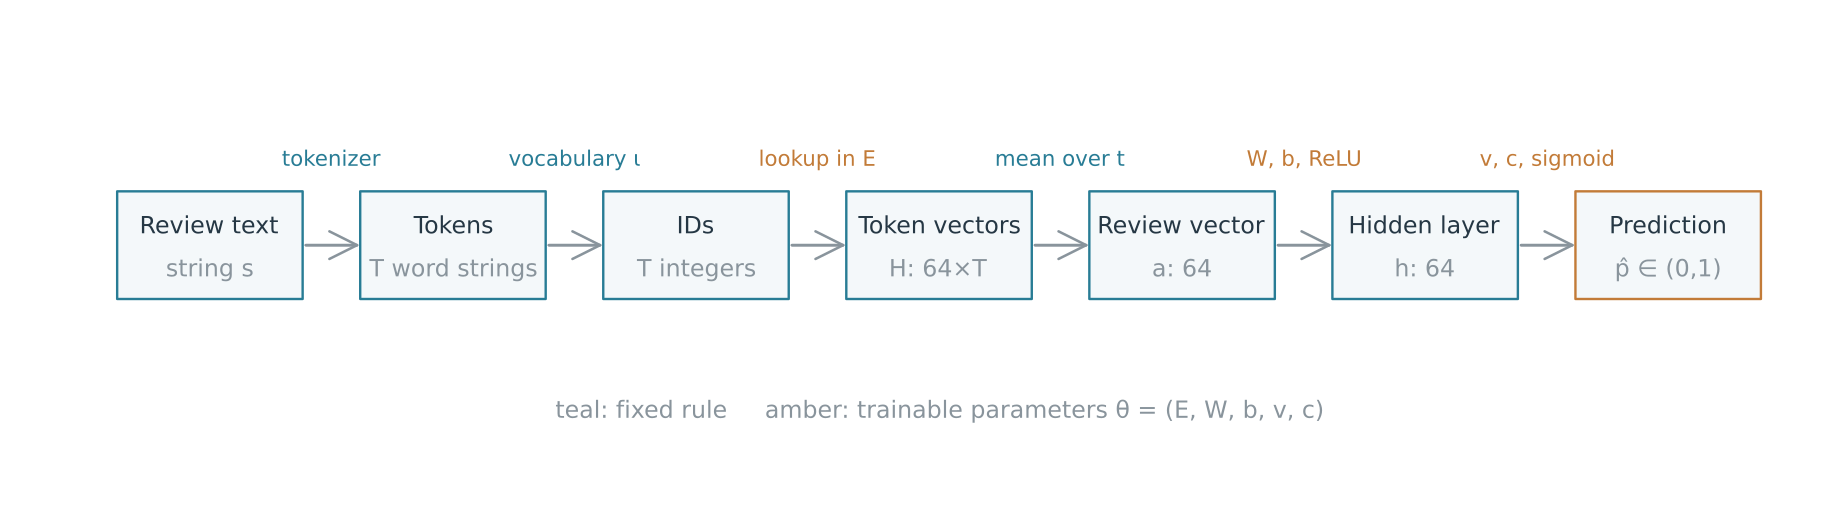

In [2]:
function pipeline_diagram()
    p=plot(xlims=(0,13.2),ylims=(-0.4,3.4),axis=false,grid=false,legend=false,size=(1150,330))
    stages=[("Review text","string s"),("Tokens","T word strings"),("IDs","T integers"),
            ("Token vectors","H: 64×T"),("Review vector","a: 64"),("Hidden layer","h: 64"),
            ("Prediction","p̂ ∈ (0,1)")]
    ops=[("tokenizer",false),("vocabulary ι",false),("lookup in E",true),
         ("mean over t",false),("W, b, ReLU",true),("v, c, sigmoid",true)]
    xs=collect(range(0.9,12.3;length=7));y=1.5
    for (k,(t,s)) in enumerate(stages)
        flow_box!(p,xs[k],y,t,s;edge=k==7 ? AMBER : TEAL)
    end
    for (k,(name,trained)) in enumerate(ops)
        flow_arrow!(p,xs[k]+0.75,xs[k+1]-0.75,y)
        annotate!(p,(xs[k]+xs[k+1])/2,y+0.85,text(name,9,trained ? AMBER : TEAL))
    end
    annotate!(p,6.6,-0.1,text("teal: fixed rule     amber: trainable parameters θ = (E, W, b, v, c)",10,GRAY))
    p
end
pipeline_diagram()

*Figure 1. The path from a review string to a probability. Only the amber operations are learned; tokenization, ID lookup, and averaging are fixed rules.*

### 1.2 Tokenize the string and assign vocabulary IDs

A **token** is one unit produced by a tokenizer. Our first tokenizer removes HTML,
lowercases English text, and extracts words while preserving apostrophe contractions.
It retains words such as `not`. Punctuation is discarded in this classifier.
This simple ASCII rule can split accented spellings into fragments; it is a stated
limitation of our tokenizer, visible in the real review below.

In [3]:
word_tokens(s)=String[m.match for m in eachmatch(r"[a-z]+(?:'[a-z]+)?",
    lowercase(replace(s,r"<[^>]*>"=>" ")))]
word_ids(text,lookup)=begin
    words=word_tokens(text)
    isempty(words) ? [1] : [get(lookup,w,1) for w in words]
end

word_ids (generic function with 1 method)

Build a vocabulary $\mathcal V$ using **training text only**. Its size is
$V=|\mathcal V|=20{,}000$, including the special entry `<unk>`.
The vocabulary map $\iota:\mathcal V\to\{1,\ldots,V\}$ assigns each entry an integer ID.
Words outside the vocabulary map to the `<unk>` ID.

For one review, the transformations are

$$s\ \xrightarrow{\text{tokenizer}}\ (w_1,\ldots,w_T)
  \ \xrightarrow{\iota}\ (x_1,\ldots,x_T),\qquad x_t=\iota(w_t).$$

$T$ is this review's number of tokens, $t$ is a token position,
$w_t$ is the token string, and $x_t$ is its integer ID.
**An ID is a table address**; adding two IDs or comparing their numerical distance
does not measure the words' meanings.

### 1.3 Prepare the IMDb splits

[IMDb](https://huggingface.co/datasets/stanfordnlp/imdb) supplies 25,000 labeled training
reviews and 25,000 labeled test reviews. Our local preparation groups identical normalized
texts, retains one same-label copy, and discards conflicting-label groups.
It reserves a stratified 10% of the remaining training pool for validation.
It also removes test duplicates and exact overlaps with the original training pool.

| Prepared split | Reviews | Purpose |
|---|---:|---|
| Training | 22,411 | Build the vocabulary and update parameters |
| Validation | 2,490 | Choose the stopping checkpoint |
| Test | 24,675 | Evaluate the selected model |

The supplied TSVs contain source row IDs, labels, and hex-encoded UTF-8 text.
Source cards and hashes accompany the data; the dataset card lists the license as `other`.
This documented filtered split is not an unmodified leaderboard benchmark.

The code chooses the **first training review in source order with 80–160 tokens** for the
calculation walkthrough. This is one observation from the full project, chosen by length,
not by whether the model predicts it correctly. Every token in that review is used.

In [4]:
function read_reviews(path)
    [begin
        id,y,s=split(line,'\t')
        (;id=parse(Int,id),y=parse(Int,y),text=String(hex2bytes(s)))
    end for line in eachline(path)]
end
function prepare_imdb(dir;max_vocab=20000,seed=31415)
    original=read_reviews(joinpath(dir,"train.tsv"))
    ws=word_tokens.(getproperty.(original,:text))
    groups=Dict{String,Vector{Int}}()
    for (i,key) in enumerate(join.(ws," "))
        push!(get!(groups,key,Int[]),i)
    end
    kept=sort([first(g) for g in values(groups) if length(unique(original[i].y for i in g))==1])
    pool,pool_ws=original[kept],ws[kept]
    train_at,val_at=Int[],Int[];rng=MersenneTwister(seed)
    for label in (0,1)
        ids=shuffle(rng,findall(r->r.y==label,pool))
        n=round(Int,0.1length(ids))
        append!(val_at,ids[1:n]);append!(train_at,ids[n+1:end])
    end
    sort!(train_at);sort!(val_at)
    counts=Dict{String,Int}()
    for i in train_at,w in pool_ws[i]
        counts[w]=get(counts,w,0)+1
    end
    ranked=sort(collect(keys(counts));by=w->(-counts[w],w))
    vocab=vcat(["<unk>"],ranked[1:min(max_vocab-1,length(ranked))])
    lookup=Dict(w=>i for (i,w) in enumerate(vocab))
    function pack(rows,tokenlists)
        ids=[isempty(w) ? [1] : [get(lookup,t,1) for t in w] for w in tokenlists]
        (;rows,ids,y=reshape(Float32[r.y for r in rows],1,:))
    end
    training=pack(pool[train_at],pool_ws[train_at])
    validation=pack(pool[val_at],pool_ws[val_at])
    test_original=read_reviews(joinpath(dir,"test.tsv"))
    test_ws=word_tokens.(getproperty.(test_original,:text))
    test_groups=Dict{String,Vector{Int}}()
    for (i,key) in enumerate(join.(test_ws," "))
        push!(get!(test_groups,key,Int[]),i)
    end
    seen=Set(join.(ws," "))
    test_at=sort([first(g) for (k,g) in test_groups if k ∉ seen &&
                  length(unique(test_original[i].y for i in g))==1])
    test=pack(test_original[test_at],test_ws[test_at])
    @assert isempty(intersect(Set(join.(pool_ws[train_at]," ")),Set(join.(pool_ws[val_at]," "))))
    (;training,validation,test,vocab,lookup,seed)
end
imdb=prepare_imdb(IMDB_DIR)
for name in (:training,:validation,:test)
    data=getproperty(imdb,name)
    @printf("%-11s %6d reviews | positive %.1f%%\n",string(name),length(data.rows),100mean(data.y))
end

V_review=length(imdb.vocab)
@assert V_review==20000
# Choose by length in source order, never by the model's prediction.
trace_at=findfirst(i->80<=length(imdb.training.ids[i])<=160,
    eachindex(imdb.training.rows))
trace_row=imdb.training.rows[trace_at]
trace_ids=imdb.training.ids[trace_at]
trace_tokens=word_tokens(trace_row.text)
T_review=length(trace_ids)
@printf("\nTraining-source row %d | %d tokens | supplied label %d\n",
    trace_row.id,T_review,trace_row.y)
excerpt=join(first(split(replace(trace_row.text,r"<[^>]*>"=>" ")),30)," ")
println("Review excerpt (all tokens are still used): ",excerpt," …")
println("\nFirst 16 tokens and vocabulary IDs (the model uses all tokens):")
for t in 1:16
    @printf("%2d  %-18s  ID %5d  table entry: %s\n",
        t,trace_tokens[t],trace_ids[t],imdb.vocab[trace_ids[t]])
end

training     22411 reviews | positive 50.1%
validation    2490 reviews | positive 50.1%
test         24675 reviews | positive 50.3%

Training-source row 3 | 115 tokens | supplied label 0


Review excerpt (all tokens are still used): This film was probably inspired by Godard's Masculin, féminin and I urge you to see that film instead. The film has two strong elements and those are, (1) the realistic …

First 16 tokens and vocabulary IDs (the model uses all tokens):


 1  this                ID    11  table entry: this
 2  film                ID    19  table entry: film
 3  was                 ID    13  table entry: was
 4  probably            ID   238  table entry: probably
 5  inspired            ID  1565  table entry: inspired
 6  by                  ID    31  table entry: by
 7  godard's            ID 17441  table entry: godard's
 8  masculin            ID     1  table entry: <unk>
 9  f                   ID  1066  table entry: f
10  minin               ID     1  table entry: <unk>
11  and                 ID     3  table entry: and
12  i                   ID    10  table entry: i
13  urge                ID  4286  table entry: urge
14  you                 ID    22  table entry: you
15  to                  ID     6  table entry: to
16  see                 ID    64  table entry: see


## 2. Define the network, one operation at a time

### 2.1 The embedding table is a parameter matrix

Choose an embedding dimension $d=64$. Each vocabulary entry has one trainable vector
$e_j\in\mathbb R^{64}$, where $j\in\{1,\ldots,20{,}000\}$ is a vocabulary ID.
Stack these vectors as **columns**:

$$E=\begin{bmatrix}e_1&e_2&\cdots&e_V\end{bmatrix}
  \in\mathbb R^{d\times V}=\mathbb R^{64\times20{,}000}.$$

The scalar $E_{rj}$ is coordinate $r$ of vocabulary entry $j$.
Thus $E[:,j]=e_j$, where the colon means “all coordinates.”
The table contains $64\times20{,}000=1{,}280{,}000$ trainable numbers.

We initialize those numbers randomly. Training changes their values; it does not change
the chosen dimension $d$. A coordinate is not assigned a meaning such as “emotion” or “noun.”
Predictive information can be spread across many coordinates.
The remaining parameter names are the hidden-layer weights $W\in\mathbb R^{64\times64}$,
hidden bias $b\in\mathbb R^{64}$, output weights $v\in\mathbb R^{64}$, and output bias
$c\in\mathbb R$. The following cell allocates all of them once, alongside $E$.
Sections 2.4–2.5 derive their operations separately.

In [5]:
function review_model(V;d=64,hidden=64,seed=2718,T=Float32)
    rng=MersenneTwister(seed)
    (;E=T(0.1).*randn(rng,T,d,V),
      W=sqrt(T(2)/d).*randn(rng,T,hidden,d),b=zeros(T,hidden),
      v=randn(rng,T,1,hidden)./sqrt(T(hidden)),c=zeros(T,1))
end

classifier_initial=review_model(V_review;d=64,hidden=64)
@printf("Embedding table E: %s = %d trainable entries\n",
    string(size(classifier_initial.E)),length(classifier_initial.E))
@assert sum(length,values(classifier_initial))==1284225

Embedding table E: (64, 20000) = 1280000 trainable entries


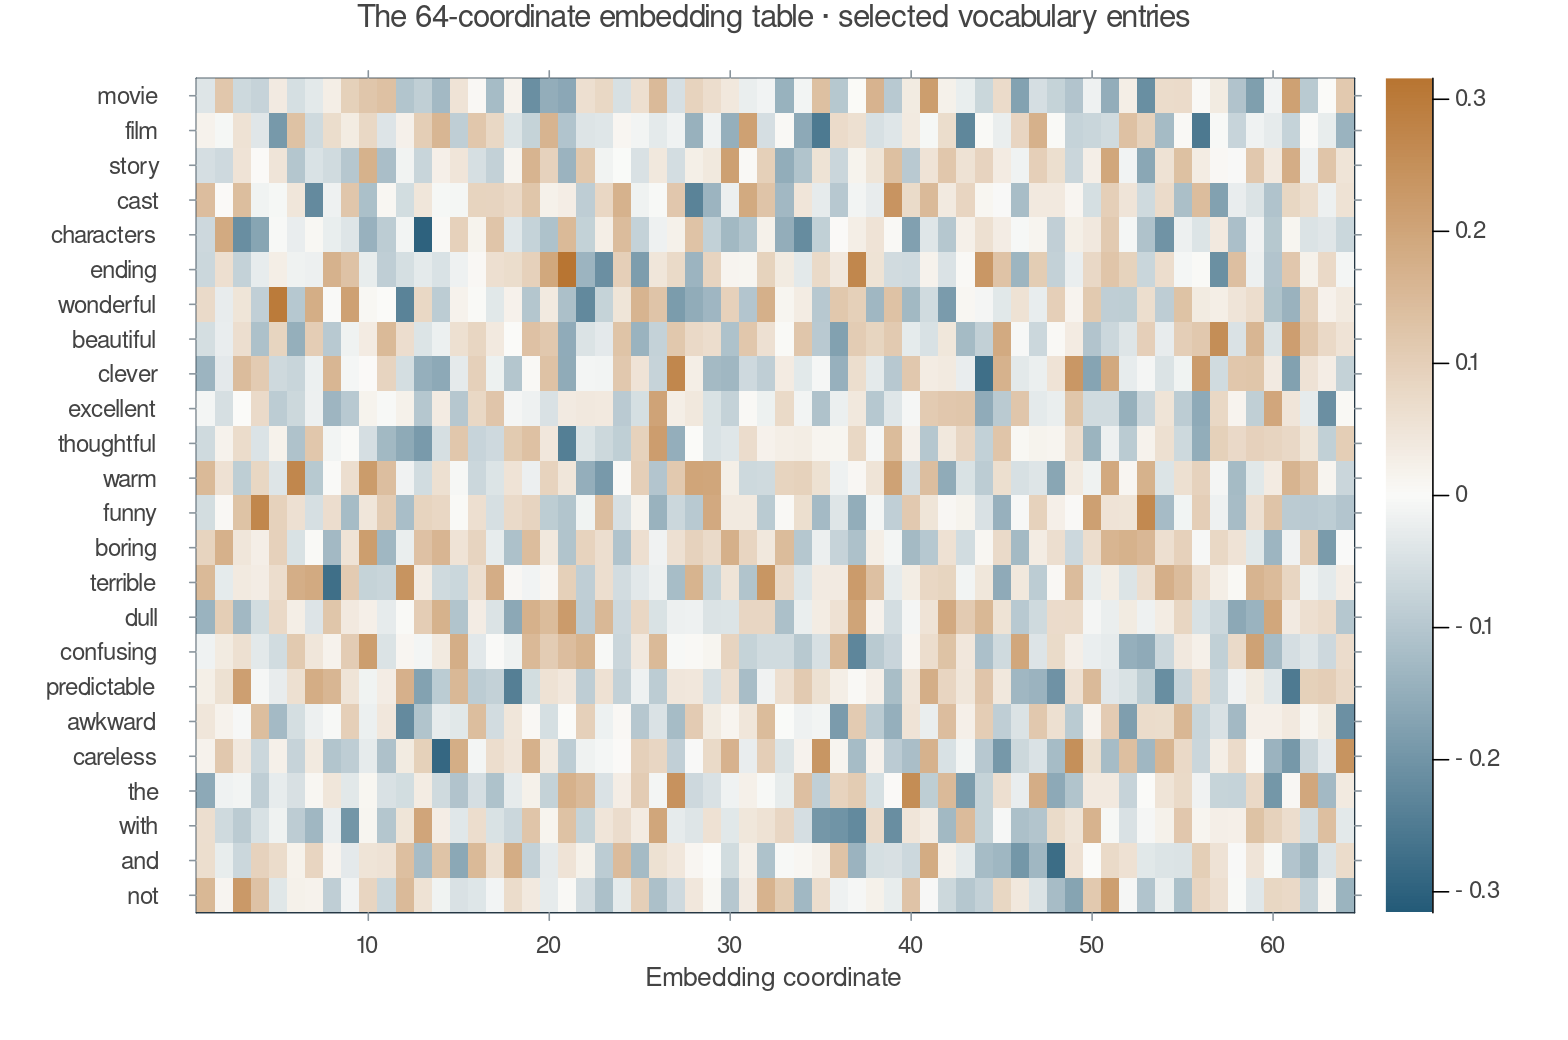

In [6]:
shown_words=["movie","film","story","cast","characters","ending","wonderful","beautiful",
    "clever","excellent","thoughtful","warm","funny","boring","terrible","dull",
    "confusing","predictable","awkward","careless","the","with","and","not"]
shown_words=filter(w->haskey(imdb.lookup,w),shown_words)
shown_ids=[imdb.lookup[w] for w in shown_words]
matrix_panel(classifier_initial.E[:,shown_ids]';rowlabels=shown_words,
    title="The 64-coordinate embedding table · selected vocabulary entries",
    xlabel="Embedding coordinate") |> p->plot(p;size=(980,650))

*Figure 2. Selected entries from the actual 64 × 20,000 initial table. All 64 coordinates are shown; the displayed words are only a view into the full vocabulary.*

### 2.2 Look up one vector for every token position

For the selected review, token position $t$ contains vocabulary ID $x_t$.
Define its looked-up vector as $\tilde e_t=e_{x_t}=E[:,x_t]$.
Collect the vectors in a new matrix:

$$H=\begin{bmatrix}\tilde e_1&\cdots&\tilde e_T\end{bmatrix}
  \in\mathbb R^{64\times T},\qquad H_{rt}=E_{r,x_t}.$$

$E$ stores a vector for **every vocabulary entry**.
$H$ contains the vectors selected by **this review**, in token order.
If the same token ID appears twice, two columns of $H$ refer to the same column of $E$.
The lookup is not a separate learned transformation: the entries of $E$ are the parameters.
Equivalently, let $o_j\in\mathbb R^V$ be the **one-hot vector** with a 1 in entry $j$ and zeros elsewhere.
Then $E\,o_{x_t}=E[:,x_t]$: multiplying by a one-hot vector picks one column.
Libraries implement the lookup as indexing because it gives the same result without forming $o_j$.

In [7]:
trace_H=classifier_initial.E[:,trace_ids]
@assert size(trace_H)==(64,T_review)
println("H has shape ",size(trace_H),": 64 coordinates × ",T_review," token positions.")
println("First five coordinates of the first three token vectors:")
for t in 1:3
    @printf("%-12s ID=%5d  %s\n",trace_tokens[t],trace_ids[t],
        string(round.(trace_H[1:5,t];digits=4)))
end

H has shape (64, 115): 64 coordinates × 115 token positions.
First five coordinates of the first three token vectors:


this         ID=   11  Float32[0.149, -0.0328, 0.063, -0.0313, -0.0949]
film         ID=   19  Float32[0.0198, -0.0067, 0.0576, -0.039, -0.1927]
was          ID=   13  Float32[0.0585, 0.0074, 0.0966, 0.059, 0.0543]


### 2.3 Mean pooling: average across tokens, coordinate by coordinate

The neural classifier needs one fixed-length vector, although reviews have different $T$.
We choose **mean pooling**. Define the review vector $a\in\mathbb R^{64}$ by

$$a=\frac{1}{T}\sum_{t=1}^T\tilde e_t
    =\frac{1}{T}\sum_{t=1}^T E[:,x_t]
    =\frac{1}{T}H\mathbf1_T.$$

Here $\mathbf1_T$ is a $T$-vector of ones. Written one coordinate at a time,

$$a_r=\frac{E_{r,x_1}+E_{r,x_2}+\cdots+E_{r,x_T}}{T},
  \qquad r=1,\ldots,64.$$

So $a_1$ averages coordinate 1 over all tokens, $a_2$ averages coordinate 2, and so on.
We average **along the token-position axis**, keeping 64 separate coordinates.
Mean pooling is a modeling choice; it is not part of the definition of an embedding.

Repeated words can be counted instead of looked up repeatedly. For vocabulary ID $j$, define

$$n_j=\sum_{t=1}^T\mathbf1\{x_t=j\},\qquad
  f_j=\frac{n_j}{T},\qquad
  f=(f_1,\ldots,f_V)^\top\in\mathbb R^V.$$

$n_j$ is a count and $f_j$ is the fraction of review tokens with ID $j$.
Regrouping the same sum gives

$$a=\sum_{j=1}^V f_j e_j=Ef,\qquad \sum_{j=1}^V f_j=1.$$

For a batch of $B$ reviews, place their frequency vectors in
$F=[f^{(1)},\ldots,f^{(B)}]\in\mathbb R^{V\times B}$.
Then $EF\in\mathbb R^{64\times B}$ contains all their means.
$F$ is observed input data, not a trainable matrix. Most entries are zero, so sparse storage
makes this exact calculation efficient without discarding any words.

Because $a$ depends on a review only through its word frequencies $f$, this representation is a
**bag of words**: it records which words occur and how often, not their order.
Classical NLP used fixed bag-of-words features (counts or TF-IDF weights) with a linear model;
here the 64 features per word are learned.

In [8]:
function word_frequencies(sequences,V;T=Float32)
    rows,cols,vals=Int[],Int[],T[]
    for (j,ids) in enumerate(sequences)
        append!(rows,ids);append!(cols,fill(j,length(ids)))
        append!(vals,fill(one(T)/length(ids),length(ids)))
    end
    sparse(rows,cols,vals,V,length(sequences))
end

function add_frequencies(data,V)
    (;data...,F=word_frequencies(data.ids,V))
end
imdb=merge(imdb,(training=add_frequencies(imdb.training,V_review),
    validation=add_frequencies(imdb.validation,V_review),
    test=add_frequencies(imdb.test,V_review)))
trace_f=imdb.training.F[:,trace_at:trace_at]
trace_mean=vec(mean(trace_H;dims=2))
@assert trace_mean≈vec(classifier_initial.E*trace_f)
@assert isapprox(sum(trace_f),1f0;atol=1f-6)
coordinate=7
@printf("Coordinate %d: sum across %d tokens = %.6f; divide by %d → %.6f\n",
    coordinate,T_review,sum(trace_H[coordinate,:]),T_review,trace_mean[coordinate])
@printf("f shape %s | E*f shape %s | all training means: 64 × %d\n",
    string(size(trace_f)),string(size(classifier_initial.E*trace_f)),length(imdb.training.rows))

Coordinate 7: sum across 115 tokens = -0.687907; divide by 115 → -0.005982


f shape (20000, 1) | E*f shape (64, 1) | all training means: 64 × 22411


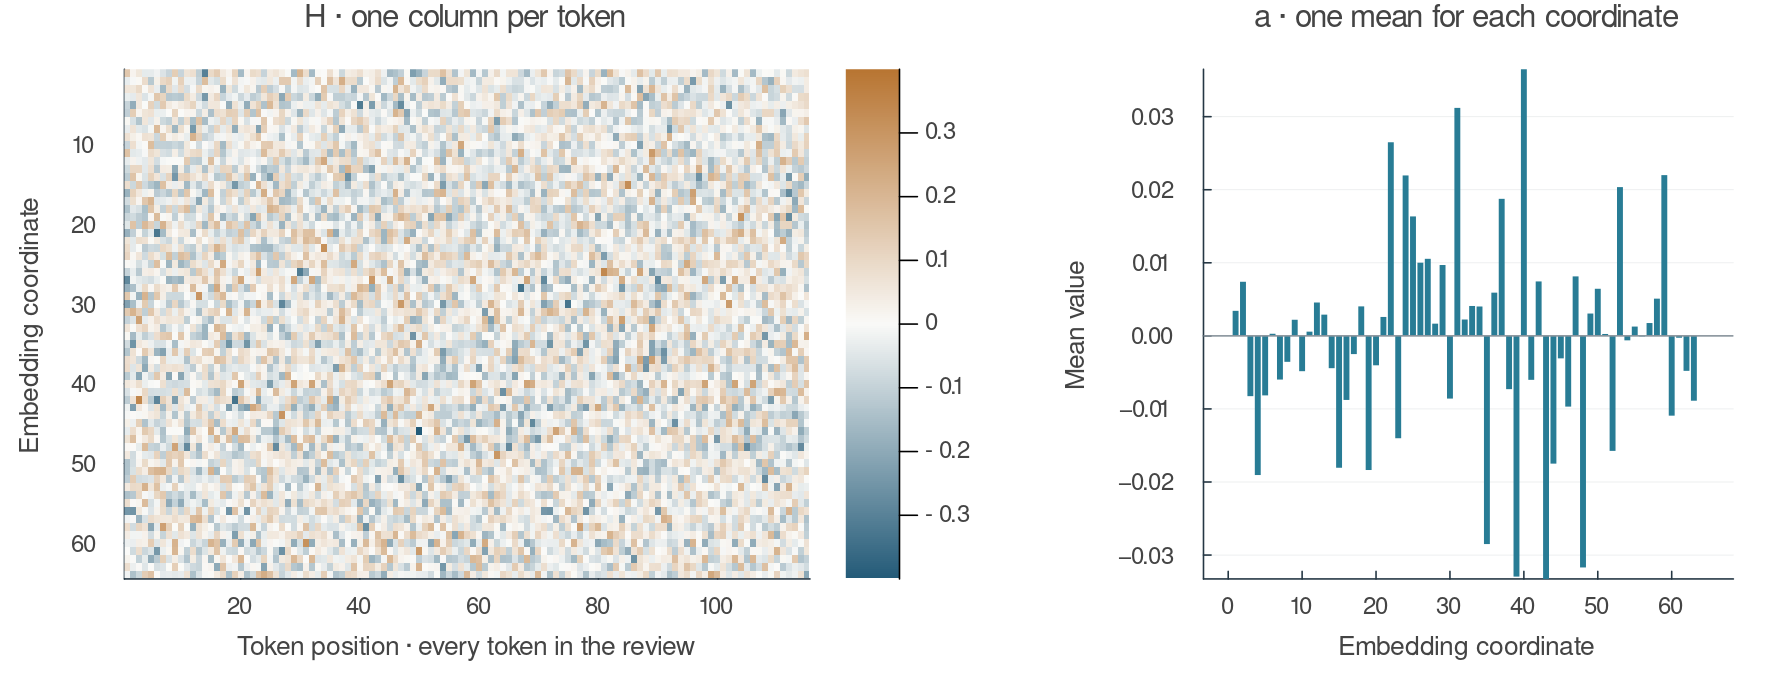

In [9]:
hp=heatmap(1:T_review,1:64,trace_H;color=DIV,
    clims=(-maximum(abs,trace_H),maximum(abs,trace_H)),colorbar=true,yflip=true,
    xlabel="Token position · every token in the review",ylabel="Embedding coordinate",
    title="H · one column per token",grid=false)
mp=bar(1:64,trace_mean;label=false,color=TEAL,linecolor=:transparent,
    xlabel="Embedding coordinate",ylabel="Mean value",
    title="a · one mean for each coordinate")
hline!(mp,[0];color=GRAY,lw=1,label=false)
plot(hp,mp;layout=grid(1,2,widths=[0.62,0.38]),size=(1120,430))

*Figure 3. Left: all token vectors of the selected real review. Averaging across its columns produces the 64 values on the right. The numerical check confirms that lookup-and-average and E times the frequency vector are the same operation.*

### 2.4 Transform the review vector with a hidden layer

Choose $m=64$ hidden units. Define a trainable weight matrix $W\in\mathbb R^{m\times d}$
and bias vector $b\in\mathbb R^m$. First compute the pre-activation vector $u$:

$$u=Wa+b\in\mathbb R^{64},\qquad
  u_k=\sum_{r=1}^{64}W_{kr}a_r+b_k,\quad k=1,\ldots,64.$$

Each hidden unit has its own weighted combination of all input coordinates.
Next apply the rectified linear unit (ReLU) to each coordinate:

$$h=\operatorname{ReLU}(u),\qquad h_k=\max(0,u_k).$$

$h\in\mathbb R^{64}$ is the hidden activation vector.
$d$ and $m$ are independent design choices; both happen to equal 64 here.
The nonlinearity lets the model learn a more flexible function than a single linear score.

### 2.5 Convert hidden activations into one probability

Define a trainable output vector $v\in\mathbb R^{64}$ and scalar bias $c\in\mathbb R$.
The output **logit** $z$ is

$$z=v^\top h+c=\sum_{k=1}^{64}v_kh_k+c\in\mathbb R.$$

It can be positive or negative and is not yet a probability. Apply the sigmoid function:

$$\hat p=\sigma(z)=\frac{1}{1+\exp(-z)}\in(0,1).$$

We predict “positive” when $\hat p\geq0.5$. The probability remains available even when
we do not convert it to a binary decision.
The code stores `v` as a $1\times64$ row matrix, so `v*h` implements $v^\top h$.
Each code column represents one review in a batch.

In [10]:
function review_forward(m,F)
    a=m.E*F
    u=m.W*a.+m.b
    h=max.(u,zero(eltype(u)))
    z=m.v*h.+m.c
    (;a,u,h,z,p=Flux.sigmoid.(z))
end
review_loss(m,F,y)=Flux.logitbinarycrossentropy(review_forward(m,F).z,y)

trace_target=imdb.training.y[:,trace_at:trace_at]
trace=review_forward(classifier_initial,trace_f)
@assert vec(trace.a)≈trace_mean
@assert trace.u[1]≈sum(classifier_initial.W[1,r]*trace_mean[r] for r in 1:64)+classifier_initial.b[1]
@assert only(trace.z)≈sum(classifier_initial.v[1,k]*trace.h[k] for k in 1:64)+only(classifier_initial.c)
println("a → u → h → z → probability shapes:")
println(size(trace.a)," → ",size(trace.u)," → ",size(trace.h)," → ",size(trace.z)," → ",size(trace.p))
@printf("Hidden unit 1: weighted sum + bias = %.6f; ReLU → %.6f\n",trace.u[1],trace.h[1])
@printf("Output: v' * h + c = %.6f; sigmoid → P(positive) = %.6f\n",only(trace.z),only(trace.p))

a → u → h → z → probability shapes:
(64, 1) → (64, 1) → (64, 1) → (1, 1) → (1, 1)
Hidden unit 1: weighted sum + bias = -0.002281; ReLU → 0.000000
Output: v' * h + c = 0.002523; sigmoid → P(positive) = 0.500631


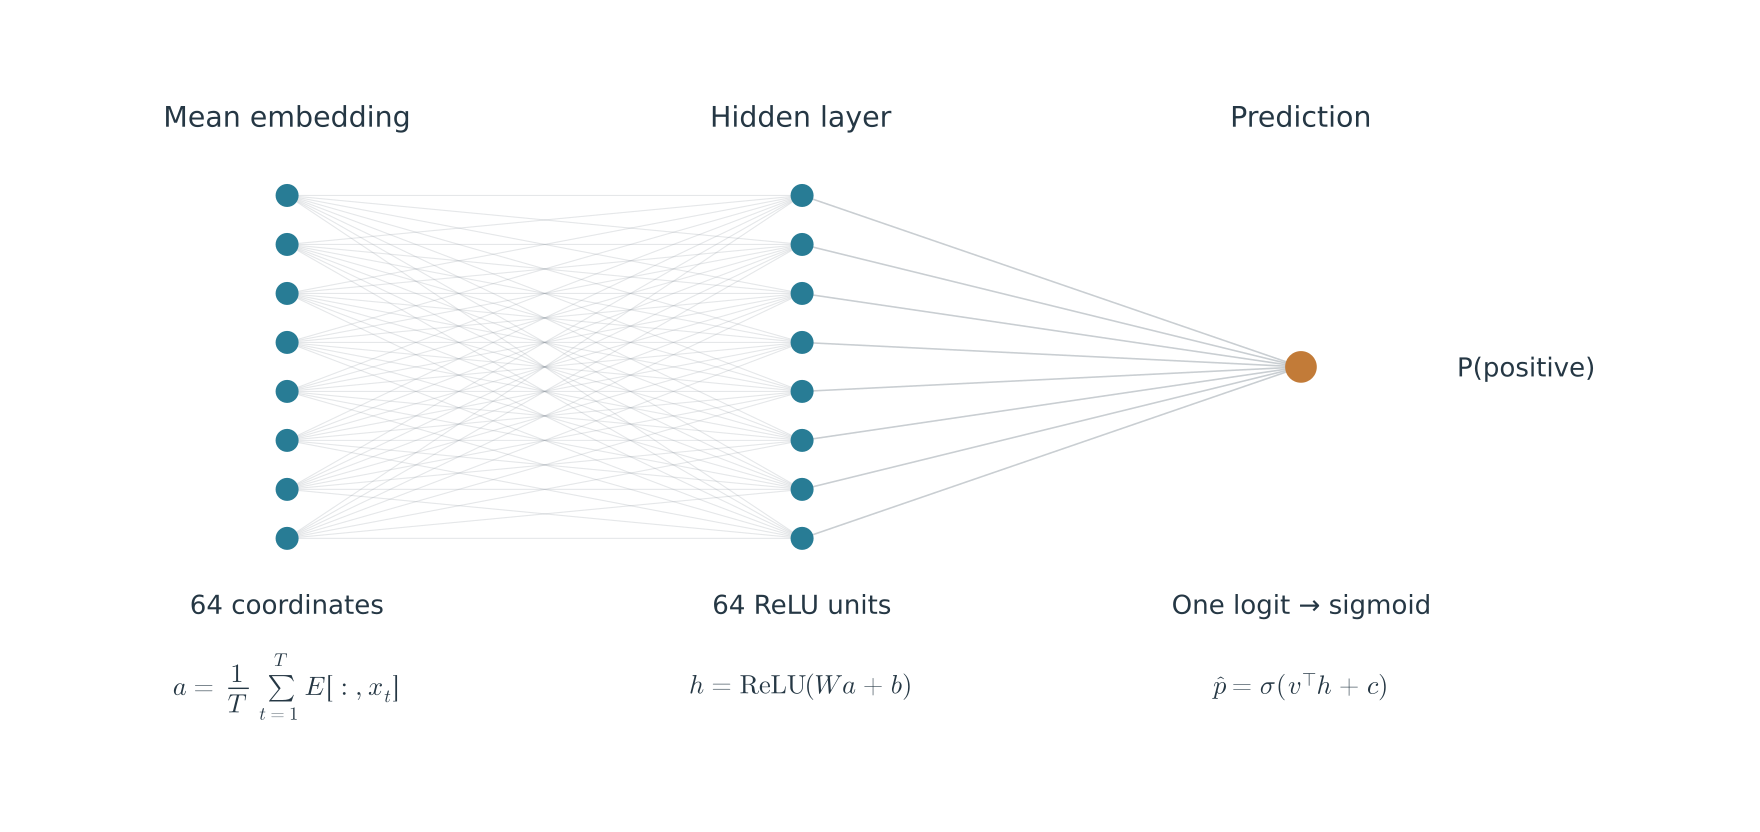

In [11]:
function classifier_diagram(d=64,hidden=64)
    p=plot(xlims=(0,10),ylims=(-1.6,8.8),axis=false,grid=false,legend=false,size=(1100,520))
    xs=[1.2,4.4,7.5];ys=collect(range(1.4,6.6;length=8))
    for a in ys,b in ys
        plot!(p,[xs[1],xs[2]],[a,b];color=GRAY,alpha=0.22,lw=0.7)
    end
    for a in ys
        plot!(p,[xs[2],xs[3]],[a,4];color=GRAY,alpha=0.45,lw=1)
    end
    scatter!(p,fill(xs[1],8),ys;ms=8,color=TEAL,markerstrokewidth=0)
    scatter!(p,fill(xs[2],8),ys;ms=8,color=TEAL,markerstrokewidth=0)
    scatter!(p,[xs[3]],[4];ms=11,color=AMBER,markerstrokewidth=0)
    annotate!(p,1.2,7.8,text("Mean embedding",12,INK))
    annotate!(p,4.4,7.8,text("Hidden layer",12,INK))
    annotate!(p,7.5,7.8,text("Prediction",12,INK))
    annotate!(p,1.2,0.4,text("$d coordinates",11,INK))
    annotate!(p,4.4,0.4,text("$hidden ReLU units",11,INK))
    annotate!(p,7.5,0.4,text("One logit → sigmoid",11,INK))
    annotate!(p,1.2,-0.85,text(L"a=\frac{1}{T}\sum_{t=1}^{T}E[:,x_t]",11,INK))
    annotate!(p,4.4,-0.85,text(L"h=\mathrm{ReLU}(Wa+b)",11,INK))
    annotate!(p,8.9,4,text("P(positive)",11,INK))
    annotate!(p,7.5,-0.85,text(L"\hat{p}=\sigma(v^\top h+c)",11,INK))
    p
end

classifier_diagram()

*Figure 4. The actual classifier has 64 mean-embedding coordinates and 64 hidden units. Eight representative nodes per layer make the connections readable; all 64 coordinates participate in the computation. The mean, hidden-layer, and output formulas appear directly in the figure.*

### 2.6 Keep parameters and activations separate

| Object | Shape for one review | Role |
|---|---|---|
| $x_1,\ldots,x_T$, $y$ | $T$ IDs and one label | Observed data |
| $E$ | $64\times20{,}000$ | Trainable vocabulary embedding table |
| $W,b$ | $64\times64$, $64$ | Trainable hidden-layer weights and biases |
| $v,c$ | $64$, scalar | Trainable output weights and bias |
| $H,a,u,h,z,\hat p$ | As defined above | Activations recomputed for this input |

The complete parameter collection is $\theta=(E,W,b,v,c)$, with

$$\underbrace{64(20{,}000)}_{E}
+\underbrace{64(64)}_W+\underbrace{64}_b+\underbrace{64}_v+\underbrace{1}_c
=1{,}284{,}225\text{ parameters}.$$

The forward pass reads $\theta$ and produces activations. It does not change the parameters.

## 3. From prediction error to parameter updates

### 3.1 Define a loss for one observed review

For label $y\in\{0,1\}$ and predicted probability $\hat p$, define binary cross-entropy:

$$L(\theta;s,y)=-y\log\hat p-(1-y)\log(1-\hat p)
=\begin{cases}-\log\hat p&y=1,\\-\log(1-\hat p)&y=0.\end{cases}$$

The loss is small when the model assigns high probability to the observed label.
It becomes large when the prediction is confidently wrong.
The code uses the equivalent, numerically stable loss computed directly from logits.

In [12]:
L_review=review_loss(classifier_initial,trace_f,trace_target)
manual_L=-only(trace_target)*log(only(trace.p))-(1-only(trace_target))*log1p(-only(trace.p))
@assert isapprox(L_review,manual_L;atol=1f-6)
@printf("Observed y = %d; predicted p = %.6f; cross-entropy = %.6f\n",
    trace_row.y,only(trace.p),L_review)

Observed y = 0; predicted p = 0.500631; cross-entropy = 0.694410


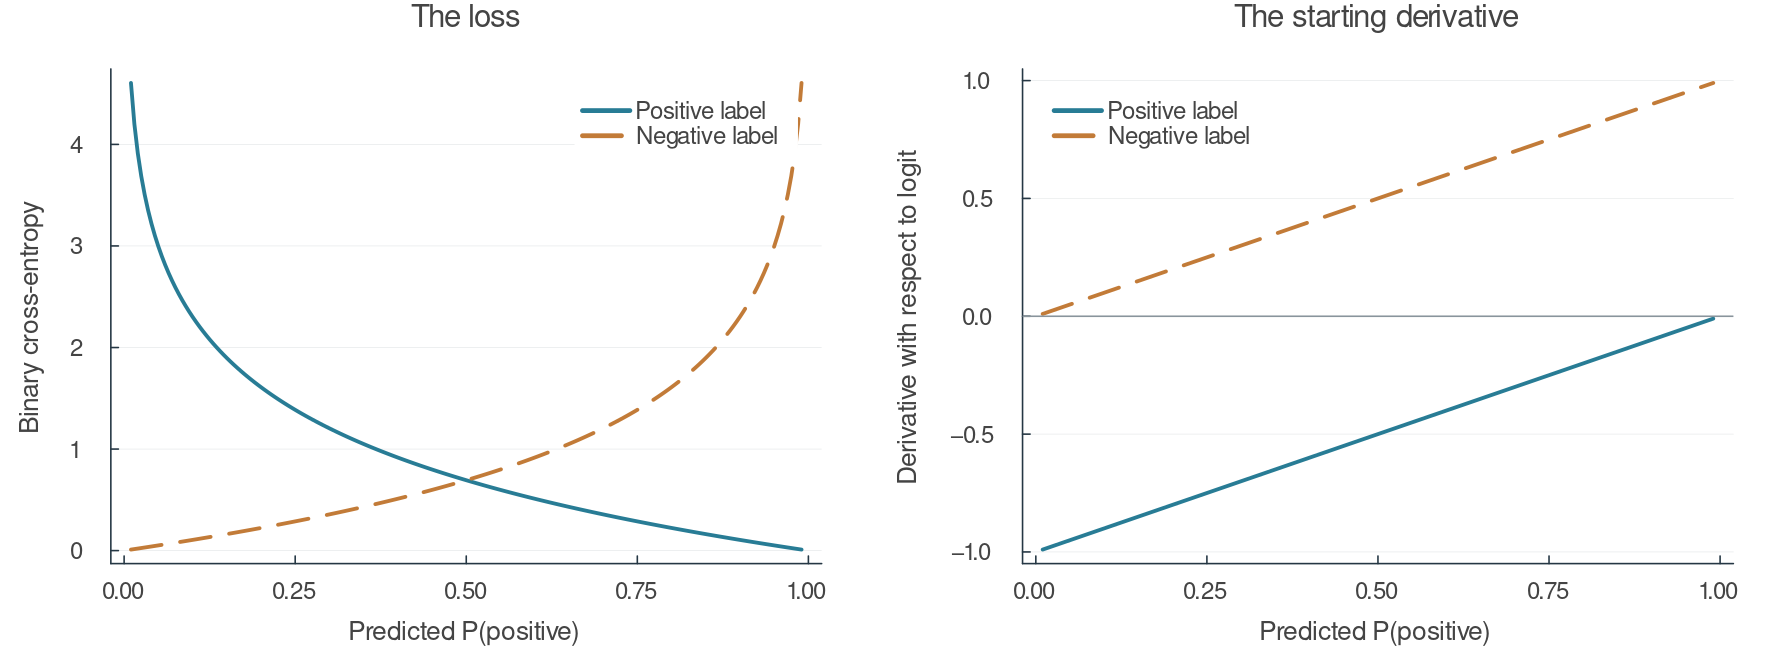

In [13]:
prob_grid=collect(0.01:0.005:0.99)
lp=plot(prob_grid,-log.(prob_grid);label="Positive label",color=TEAL,
    xlabel="Predicted P(positive)",ylabel="Binary cross-entropy",title="The loss")
plot!(lp,prob_grid,-log1p.(-prob_grid);label="Negative label",color=AMBER,linestyle=:dash)
gp=plot(prob_grid,prob_grid.-1;label="Positive label",color=TEAL,
    xlabel="Predicted P(positive)",ylabel="Derivative with respect to logit",title="The starting derivative")
plot!(gp,prob_grid,prob_grid;label="Negative label",color=AMBER,linestyle=:dash)
hline!(gp,[0];color=GRAY,label=false,lw=1)
plot(lp,gp;layout=(1,2),size=(1120,420))

*Figure 5. Left: how the probability affects cross-entropy. Right: the derivative with respect to the logit, derived next. The horizontal axis in both panels is the predicted probability.*

### 3.2 Draw the computation graph

The forward pass is a chain of simple operations. Backpropagation walks the same chain in reverse,
multiplying local derivatives. Figure 6 shows both directions; Sections 3.3–3.5 derive each
backward label, and the code checks every one against automatic differentiation.

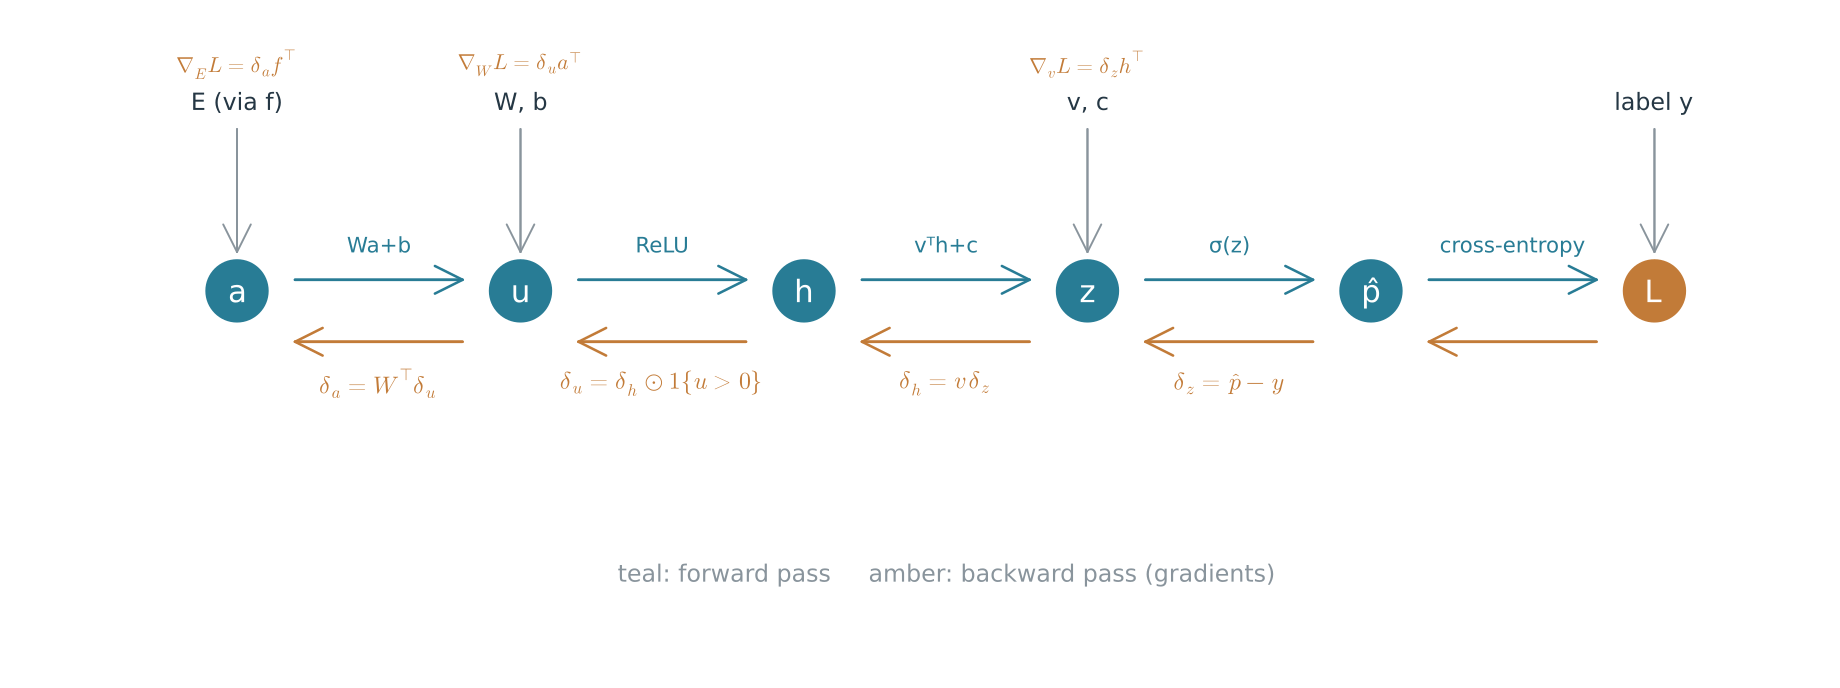

In [14]:
function backprop_diagram()
    p=plot(xlims=(0,13),ylims=(-1.3,4.6),axis=false,grid=false,legend=false,size=(1150,430))
    names=["a","u","h","z","p̂","L"];xs=collect(range(1.0,12.0;length=6));y=2.0
    for (k,n) in enumerate(names)
        scatter!(p,[xs[k]],[y];ms=22,color=k==6 ? AMBER : TEAL,markerstrokewidth=0)
        annotate!(p,xs[k],y,text(n,13,:white))
    end
    fwd=["Wa+b","ReLU","vᵀh+c","σ(z)","cross-entropy"]
    for k in 1:5
        flow_arrow!(p,xs[k]+0.45,xs[k+1]-0.45,y+0.12;color=TEAL)
        annotate!(p,(xs[k]+xs[k+1])/2,y+0.5,text(fwd[k],9,TEAL))
        plot!(p,[xs[k+1]-0.45,xs[k]+0.45],[y-0.55,y-0.55];arrow=true,color=AMBER,lw=1.6)
    end
    back=[L"\delta_a=W^\top\delta_u",L"\delta_u=\delta_h\odot 1\{u>0\}",
          L"\delta_h=v\,\delta_z",L"\delta_z=\hat{p}-y",""]
    for k in 1:4
        annotate!(p,(xs[k]+xs[k+1])/2,y-1.0,text(back[k],10,AMBER))
    end
    params=[(1,"E (via f)",L"\nabla_E L=\delta_a f^\top"),(2,"W, b",L"\nabla_W L=\delta_u a^\top"),
            (4,"v, c",L"\nabla_v L=\delta_z h^\top"),(6,"label y","")]
    for (k,name,grad) in params
        x=xs[k]
        plot!(p,[x,x],[y+1.75,y+0.42];arrow=true,color=GRAY,lw=1.2)
        annotate!(p,x,y+2.05,text(name,10,INK))
        grad=="" || annotate!(p,x,y+2.45,text(grad,9,AMBER))
    end
    annotate!(p,6.5,-1.05,text("teal: forward pass     amber: backward pass (gradients)",10,GRAY))
    p
end
backprop_diagram()

*Figure 6. Forward pass (teal, left to right) and backward pass (amber, right to left). Each backward label multiplies the incoming gradient by a local derivative; parameter gradients (top) branch off the chain.*

### 3.3 Differentiate the output, without skipping the sigmoid

For an intermediate vector $q$, write $\delta_q=\partial L/\partial q$.
Begin with the two scalar derivatives:

$$\frac{\partial L}{\partial\hat p}
=-\frac{y}{\hat p}+\frac{1-y}{1-\hat p},
\qquad
\frac{\partial\hat p}{\partial z}=\hat p(1-\hat p).$$

The chain rule gives

$$\delta_z=\frac{\partial L}{\partial z}
=\left(-\frac{y}{\hat p}+\frac{1-y}{1-\hat p}\right)\hat p(1-\hat p)
=-y(1-\hat p)+(1-y)\hat p
=\hat p-y.$$

For a positive review, $\delta_z<0$, so a small descent step on $z$ would raise it.
For a negative review, $\delta_z>0$, so descent would lower it.
The optimizer actually changes parameters; the derivatives below tell it how each parameter affects $z$.

### 3.4 Continue backward through the output and hidden layer

Since $z=\sum_k v_kh_k+c$,

$$\frac{\partial L}{\partial v_k}=\delta_z h_k,\qquad
  \frac{\partial L}{\partial c}=\delta_z,\qquad
  (\delta_h)_k=\delta_z v_k.$$

For ReLU, a positive pre-activation has derivative 1 and a negative one has derivative 0.
We use derivative 0 at its kink, $u_k=0$. Therefore

$$\delta_u=\delta_h\odot\mathbf1_{\{u>0\}},$$

where $\odot$ means coordinate-by-coordinate multiplication.
Using $u_k=\sum_r W_{kr}a_r+b_k$, each derivative is

$$\frac{\partial L}{\partial W_{kr}}=(\delta_u)_k a_r,\qquad
  \frac{\partial L}{\partial b_k}=(\delta_u)_k,\qquad
  (\delta_a)_r=\sum_{k=1}^{64}W_{kr}(\delta_u)_k.$$

In matrix form:

$$\nabla_W L=\delta_u a^\top,\qquad
  \nabla_b L=\delta_u,\qquad
  \delta_a=W^\top\delta_u.$$

### 3.5 Continue through the average to the embedding table

Recall the exact scalar mean $a_r=\sum_j f_jE_{rj}$.
The frequencies $f_j$ are fixed for this review, so

$$\frac{\partial a_r}{\partial E_{rj}}=f_j=\frac{n_j}{T},\qquad
  \frac{\partial L}{\partial E_{rj}}=(\delta_a)_r\frac{n_j}{T}.$$

Across all coordinates and vocabulary entries,

$$\nabla_E L=\delta_a f^\top\in\mathbb R^{64\times20{,}000},
  \qquad \nabla_{E[:,j]}L=\frac{n_j}{T}\delta_a.$$

An unused word has $n_j=0$, hence zero gradient for this review.
A repeated word contributes through every occurrence.
Even a neutral word can move after one example; learning across many reviews separates
predictive patterns from incidental co-occurrence.
**There is no target embedding to copy. The prediction loss supplies its training signal.**

### 3.6 Apply one simultaneous parameter update

Let $\eta>0$ be the learning rate. Plain gradient descent applies

$$\theta_{\mathrm{new}}=\theta_{\mathrm{old}}
  -\eta\nabla_\theta L(\theta_{\mathrm{old}}).$$

For one embedding entry, this is explicitly

$$E_{rj}^{\mathrm{new}}
=E_{rj}^{\mathrm{old}}
-\eta\left[\frac{n_j}{T}(\delta_a)_r\right]_{\theta=\theta_{\mathrm{old}}}.$$

All derivatives are computed using the **old** parameters before any are updated.
Backpropagation computes gradients; the optimizer uses them to update parameters.
Activations such as $a$ and $h$ are recomputed on the next forward pass, not stored as learned parameters.

The cell below calculates every derivative by hand, checks it against Flux automatic
differentiation on the full model, and prints the actual numbers for one embedding update.
It leaves the original initialization intact for the training experiment.

Manual / AD maximum difference: 0.00e+00
One step on the full model: loss 0.694410 → 0.657733


Token 'the', ID 2, occurs 9/115 times


E[7,2]: 0.0094454 − 0.1 × (0.0099652) = 0.0084489
19920 unused vocabulary entries have exactly zero embedding gradient for this review.


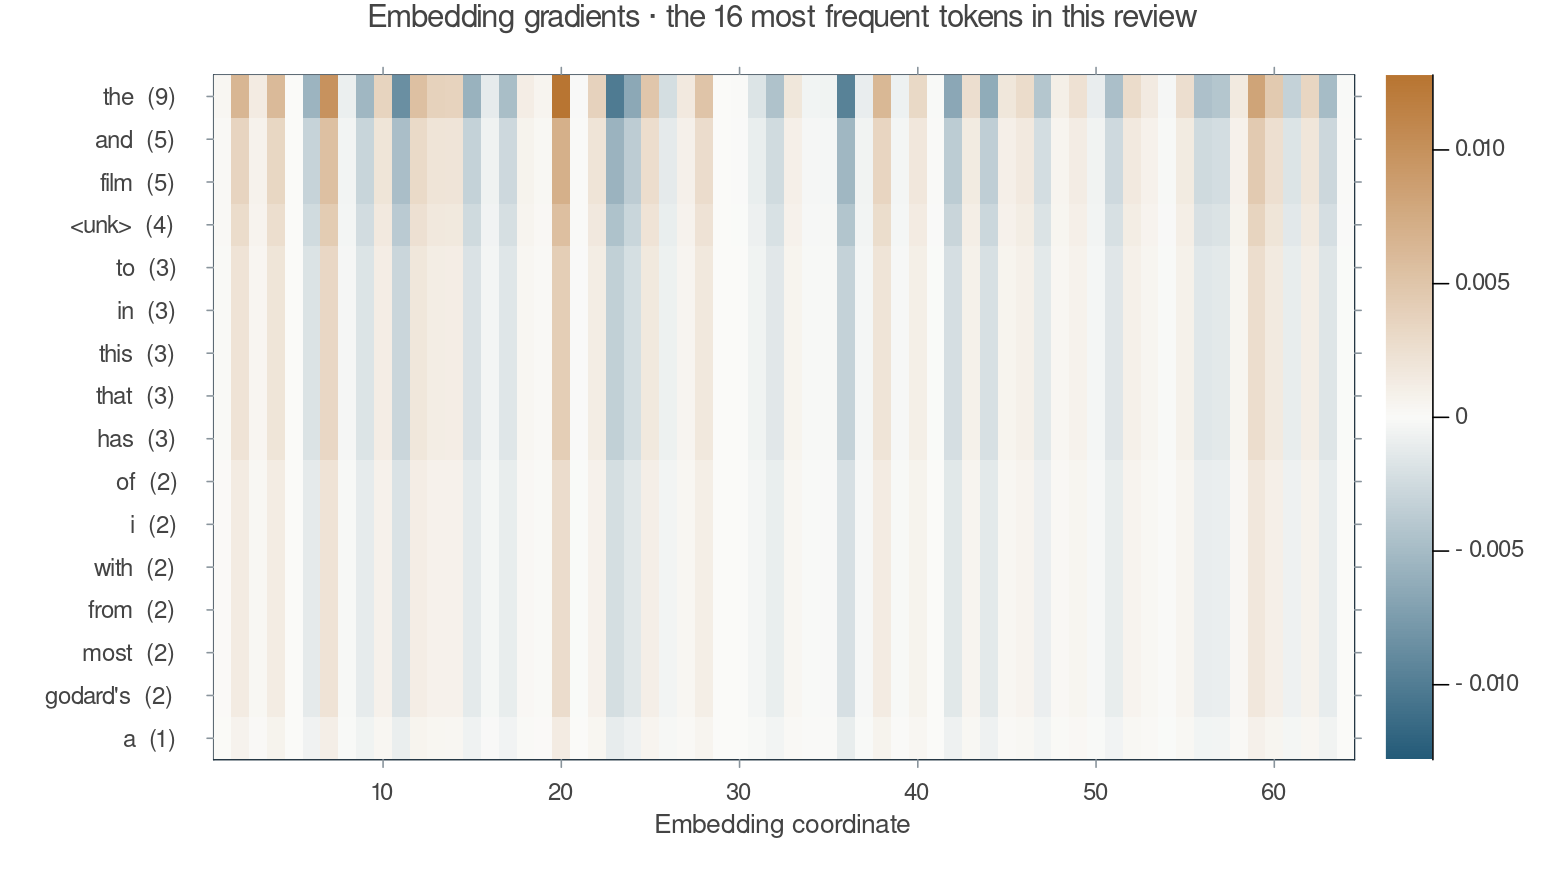

In [15]:
delta_z=trace.p-trace_target
delta_h=classifier_initial.v'*delta_z
delta_u=delta_h.*(trace.u.>0)
delta_a=classifier_initial.W'*delta_u
manual_gradient=(E=Matrix(delta_a*trace_f'),W=delta_u*trace.a',
    b=vec(delta_u),v=delta_z*trace.h',c=vec(delta_z))
ad_gradient=Flux.gradient(m->review_loss(m,trace_f,trace_target),classifier_initial)[1]
gradient_error=maximum(maximum(abs.(getproperty(manual_gradient,k).-getproperty(ad_gradient,k)))
    for k in keys(classifier_initial))
@assert gradient_error<2f-6
unused=setdiff(1:V_review,trace_ids)
@assert all(iszero,ad_gradient.E[:,unused])
eta=0.1f0
one_step=map((p,g)->p.-eta.*g,classifier_initial,ad_gradient)
@assert review_loss(one_step,trace_f,trace_target)<L_review
word_counts=Dict(j=>count(==(j),trace_ids) for j in unique(trace_ids))
gradient_ids=sort(collect(keys(word_counts));by=j->(-word_counts[j],j))[1:16]
focus_id=first(gradient_ids);r=7
@printf("Manual / AD maximum difference: %.2e\n",gradient_error)
@printf("One step on the full model: loss %.6f → %.6f\n",
    L_review,review_loss(one_step,trace_f,trace_target))
@printf("Token '%s', ID %d, occurs %d/%d times\n",
    imdb.vocab[focus_id],focus_id,word_counts[focus_id],T_review)
@printf("E[7,%d]: %.7f − %.1f × (%.7f) = %.7f\n",
    focus_id,classifier_initial.E[r,focus_id],eta,ad_gradient.E[r,focus_id],one_step.E[r,focus_id])
@printf("%d unused vocabulary entries have exactly zero embedding gradient for this review.\n",length(unused))
gradient_labels=[string(imdb.vocab[j],"  (",word_counts[j],")") for j in gradient_ids]
matrix_panel(ad_gradient.E[:,gradient_ids]';rowlabels=gradient_labels,
    title="Embedding gradients · the 16 most frequent tokens in this review",
    xlabel="Embedding coordinate") |> p->plot(p;size=(980,550))

*Figure 7. A real review produces gradients in the full 64 × 20,000 table. The displayed rows are its 16 most frequent vocabulary IDs; parentheses give occurrence counts. Repeated words receive proportionally larger contributions. The code also verifies zero gradients for every unused entry.*

## 4. Train and evaluate the IMDb network

### 4.1 Average gradients across a batch

For a batch $\mathcal B$ of $B$ reviews, the objective and its derivative are

$$L_{\mathcal B}(\theta)=\frac1B\sum_{n\in\mathcal B}L(\theta;s_n,y_n),
\qquad
\nabla_\theta L_{\mathcal B}=\frac1B\sum_{n\in\mathcal B}\nabla_\theta L_n.$$

The training loop shuffles the training reviews, takes batches of 128, computes this mean loss,
backpropagates, and updates all parameters. One **epoch** visits every training review once.
The last batch can be smaller than 128.

We use Adam instead of plain gradient descent for the full fit. For update index $q$ and
batch gradient $g_q$, Adam keeps two running arrays, initially $m_0=v_0=0$:

$$m_q=\beta_1m_{q-1}+(1-\beta_1)g_q,\qquad
  v_q=\beta_2v_{q-1}+(1-\beta_2)(g_q\odot g_q).$$

With bias correction $\hat m_q=m_q/(1-\beta_1^q)$ and
$\hat v_q=v_q/(1-\beta_2^q)$, its update is

$$\theta_q=\theta_{q-1}
-\eta\frac{\hat m_q}{\sqrt{\hat v_q}+\epsilon}.$$

All operations in this update are coordinatewise; $\beta_1,\beta_2\in[0,1)$ control smoothing
and $\epsilon>0$ stabilizes the denominator. These optimizer arrays are distinct from the
classifier's output vector $v$. Adam changes the update rule, not the forward equations or chain rule.

### 4.2 Fit the same 1.28-million-parameter model

The fit starts from the exact initialization used above.
It uses eight epochs, learning rate 0.003, and all tokenized words in every review.
After each epoch, validation cross-entropy determines whether to keep that checkpoint.
Only after selection is the test set evaluated.

`TRAIN_SENTIMENT=true` retrains the model; false loads its saved result.
The ten-minute fit budget is checked between updates; setup and final evaluation add time.

In [16]:
function evaluate_reviews(m,data;batch_size=512)
    probabilities=Float32[];total=0.0
    for start in 1:batch_size:length(data.rows)
        idx=start:min(start+batch_size-1,length(data.rows))
        trace=review_forward(m,data.F[:,idx])
        append!(probabilities,vec(trace.p))
        total+=Float64(Flux.logitbinarycrossentropy(trace.z,data.y[:,idx]))*length(idx)
    end
    truth=vec(data.y).==1;pred=probabilities.>=0.5
    cm=[sum((truth.==a).&(pred.==p)) for a in (false,true),p in (false,true)]
    (;loss=total/length(truth),accuracy=mean(truth.==pred),probabilities,confusion=cm,
      f1=2cm[2,2]/max(2cm[2,2]+cm[1,2]+cm[2,1],1))
end
function train_reviews(data;d=64,hidden=64,epochs=8,batch_size=128,lr=0.003f0,budget=600)
    started=time();initial=deepcopy(classifier_initial)
    @assert size(initial.E)==(d,length(data.vocab)) && size(initial.W)==(hidden,d)
    m=deepcopy(initial);opt=Flux.setup(Flux.Adam(lr),m);rng=MersenneTwister(2719)
    tr,va=evaluate_reviews(m,data.training),evaluate_reviews(m,data.validation)
    history=[(;epoch=0,train_loss=tr.loss,val_loss=va.loss,train_acc=tr.accuracy,val_acc=va.accuracy)]
    best,best_loss,best_epoch=deepcopy(m),va.loss,0
    for epoch in 1:epochs
        order=randperm(rng,length(data.training.rows))
        for start in 1:batch_size:length(order)
            time()-started>budget && break
            idx=order[start:min(start+batch_size-1,length(order))]
            F,y=data.training.F[:,idx],data.training.y[:,idx]
            loss,g=Flux.withgradient(p->review_loss(p,F,y),m)
            @assert isfinite(loss)
            Flux.update!(opt,m,g[1])
        end
        tr,va=evaluate_reviews(m,data.training),evaluate_reviews(m,data.validation)
        push!(history,(;epoch,train_loss=tr.loss,val_loss=va.loss,train_acc=tr.accuracy,val_acc=va.accuracy))
        if va.loss<best_loss
            best,best_loss,best_epoch=deepcopy(m),va.loss,epoch
        end
        @printf("Epoch %d | train %.3f | validation %.3f | val accuracy %.1f%%\n",
            epoch,tr.loss,va.loss,100va.accuracy)
        time()-started>budget && break
    end
    test=evaluate_reviews(best,data.test)
    (;model=best,initial,history,best_epoch,test,seconds=time()-started,
      vocab=data.vocab,config=(;d,hidden,epochs,batch_size,lr))
end
TRAIN_SENTIMENT=true
sentiment=TRAIN_SENTIMENT ? train_reviews(imdb) : deserialize(joinpath(RESULTS,"sentiment.jls"))
@assert sentiment.vocab==imdb.vocab
@assert sentiment.initial==classifier_initial
TRAIN_SENTIMENT && serialize(joinpath(RESULTS,"sentiment.jls"),sentiment)
@printf("%s parameters | selected epoch %d | fit %.1f seconds\n",
    string(sum(length,values(sentiment.model))),sentiment.best_epoch,sentiment.seconds)

Epoch 1 | train 0.178 | validation 0.263 | val accuracy 89.2%


Epoch 2 | train 0.106 | validation 0.268 | val accuracy 89.4%


Epoch 3 | train 0.056 | validation 0.294 | val accuracy 89.0%


Epoch 4 | train 0.038 | validation 0.361 | val accuracy 88.8%


Epoch 5 | train 0.021 | validation 0.450 | val accuracy 87.4%


Epoch 6 | train 0.007 | validation 0.505 | val accuracy 88.1%


Epoch 7 | train 0.003 | validation 0.581 | val accuracy 88.0%


Epoch 8 | train 0.002 | validation 0.623 | val accuracy 88.1%


1284225 parameters | selected epoch 1 | fit 13.6 seconds


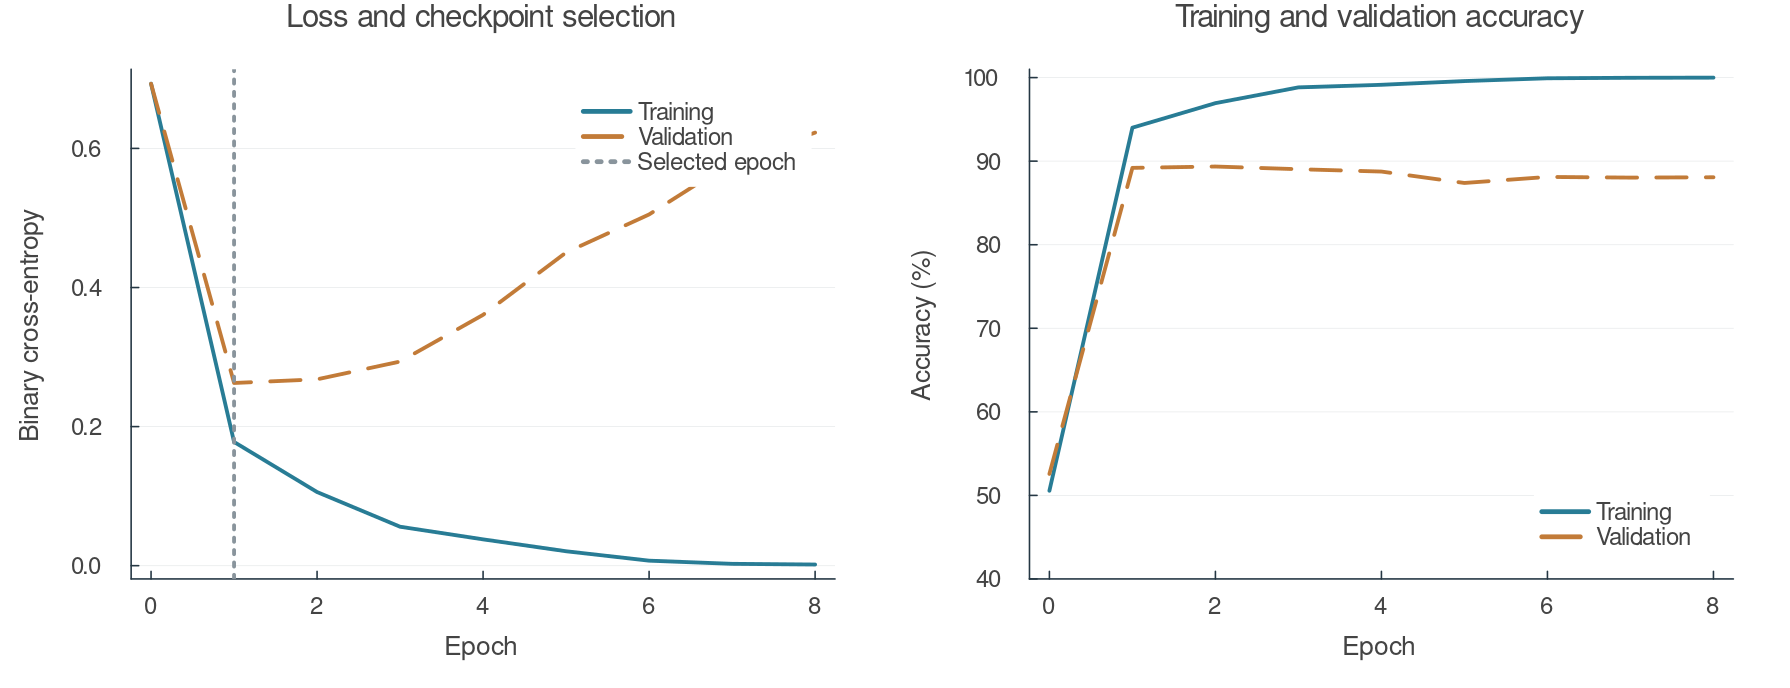

In [17]:
epochs=[h.epoch for h in sentiment.history]
p1=plot(epochs,[h.train_loss for h in sentiment.history];label="Training",color=TEAL,
    xlabel="Epoch",ylabel="Binary cross-entropy",title="Loss and checkpoint selection")
plot!(p1,epochs,[h.val_loss for h in sentiment.history];label="Validation",color=AMBER,linestyle=:dash)
vline!(p1,[sentiment.best_epoch];label="Selected epoch",color=GRAY,linestyle=:dot)
p2=plot(epochs,100 .* [h.train_acc for h in sentiment.history];label="Training",color=TEAL,
    xlabel="Epoch",ylabel="Accuracy (%)",ylims=(40,101),title="Training and validation accuracy")
plot!(p2,epochs,100 .* [h.val_acc for h in sentiment.history];label="Validation",color=AMBER,linestyle=:dash)
plot(p1,p2;layout=(1,2),size=(1120,430))

*Figure 8. Training and validation use different reviews. Falling training loss can coexist with rising validation loss; the dotted line identifies the selected checkpoint.*

### 4.3 Measure performance and inspect mistakes

Let $\hat y_n=\mathbf1\{\hat p_n\geq0.5\}$ and let $N_{\rm test}$ be the number of test reviews.

$$\mathrm{Accuracy}=\frac1{N_{\rm test}}\sum_n\mathbf1\{\hat y_n=y_n\}.$$

A **true positive** (TP) is a positive review predicted positive.
A **false positive** (FP) is a negative review predicted positive.
A **false negative** (FN) is a positive review predicted negative.
Positive-class F1 combines these counts:

$$F_1=\frac{2TP}{2TP+FP+FN}.$$

The confusion matrix uses actual labels in rows and predicted labels in columns.
We also compare accuracy with the majority-label rule selected from training labels.

Filtered test: 24675 reviews | accuracy 87.78% | positive F1 0.8730 | loss 0.2969


Training-majority baseline: 50.30%


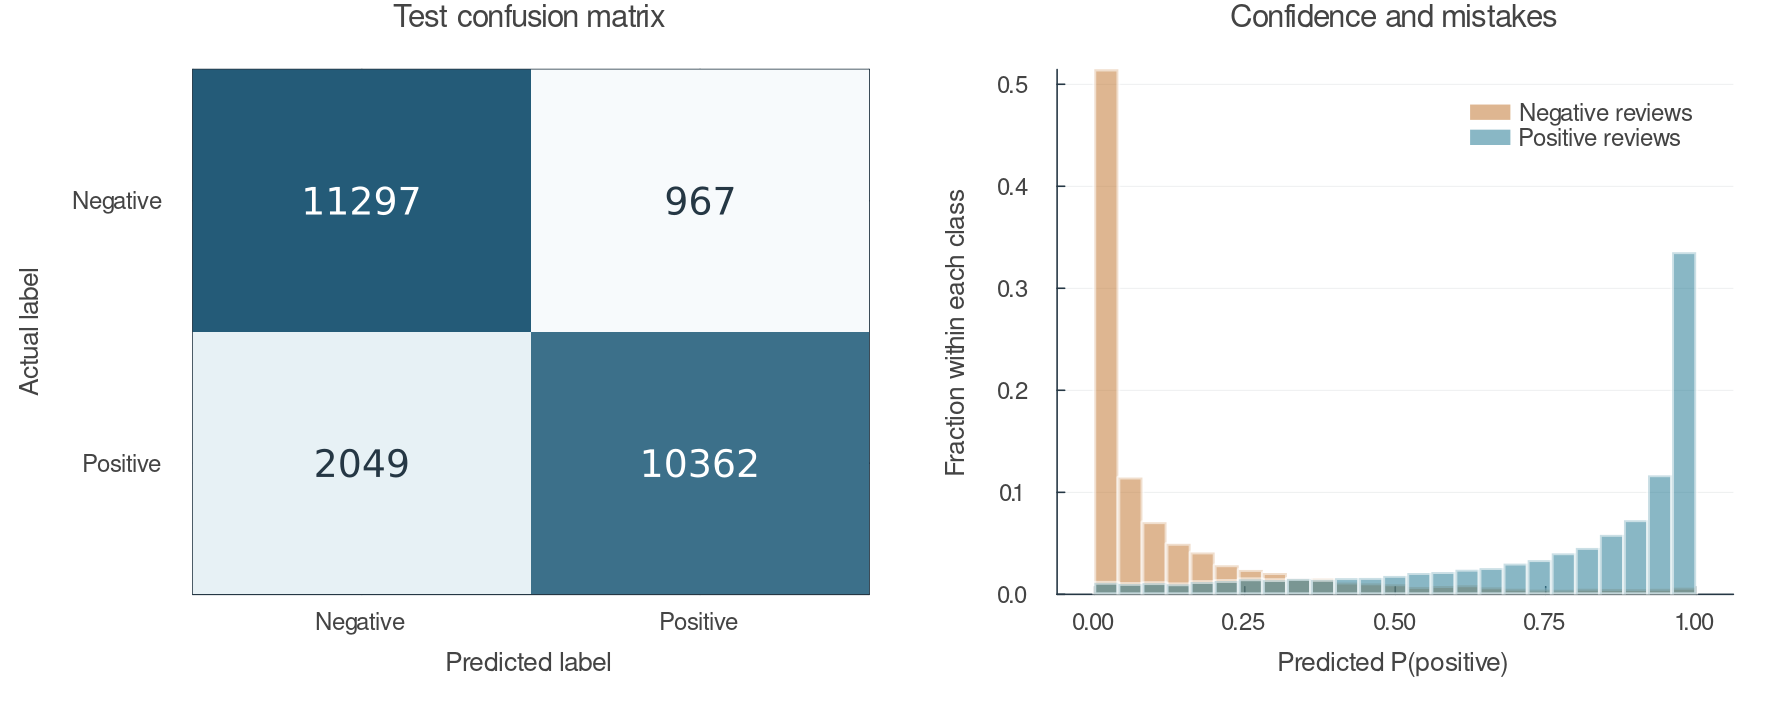

In [18]:
cm=sentiment.test.confusion
@printf("Filtered test: %d reviews | accuracy %.2f%% | positive F1 %.4f | loss %.4f\n",
    length(imdb.test.rows),100sentiment.test.accuracy,sentiment.test.f1,sentiment.test.loss)
majority=mean(imdb.training.y)>=0.5
@printf("Training-majority baseline: %.2f%%\n",100mean((vec(imdb.test.y).>=0.5).==majority))
cp=heatmap(1:2,1:2,cm;color=SEQ,colorbar=false,yflip=true,grid=false,framestyle=:box,
    xticks=(1:2,["Negative","Positive"]),yticks=(1:2,["Negative","Positive"]),
    xlabel="Predicted label",ylabel="Actual label",title="Test confusion matrix")
for a in 1:2,p in 1:2
    annotate!(cp,p,a,text(string(cm[a,p]),16,cm[a,p]>maximum(cm)/2 ? :white : INK))
end
neg=sentiment.test.probabilities[vec(imdb.test.y).==0]
pos=sentiment.test.probabilities[vec(imdb.test.y).==1]
hp=histogram(neg;bins=0:0.04:1,normalize=:probability,color=AMBER,alpha=0.55,
    linecolor=:white,label="Negative reviews",xlabel="Predicted P(positive)",
    ylabel="Fraction within each class",title="Confidence and mistakes")
histogram!(hp,pos;bins=0:0.04:1,normalize=:probability,color=TEAL,alpha=0.55,
    linecolor=:white,label="Positive reviews")
plot(cp,hp;layout=(1,2),size=(1120,440))

*Figure 9. The matrix reports counts. Each probability histogram is normalized within its actual class, making confident errors and ambiguous predictions visible.*

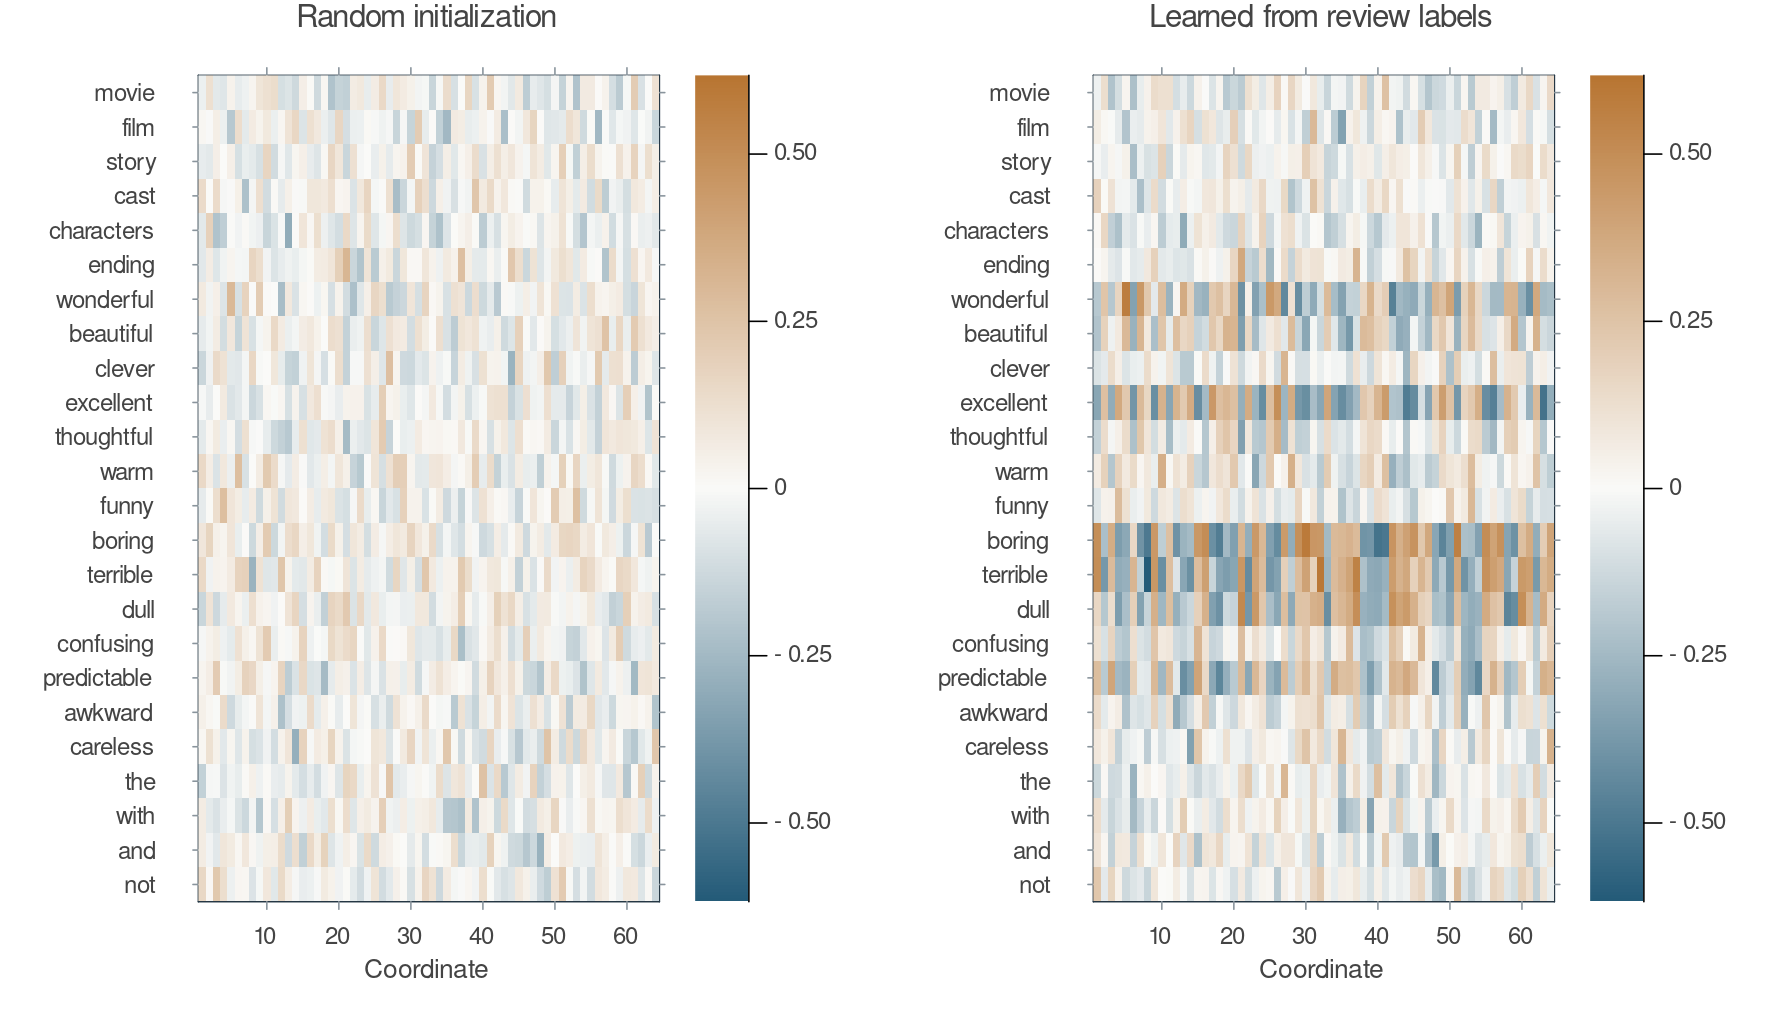

In [19]:
real_words=filter(w->haskey(imdb.lookup,w),shown_words)
real_ids=[imdb.lookup[w] for w in real_words]
E0,E1=sentiment.initial.E[:,real_ids]',sentiment.model.E[:,real_ids]'
scale=max(maximum(abs,E0),maximum(abs,E1))
ep0=matrix_panel(E0;rowlabels=real_words,title="Random initialization",limit=scale)
ep1=matrix_panel(E1;rowlabels=real_words,title="Learned from review labels",limit=scale)
plot(ep0,ep1;layout=(1,2),size=(1120,640))

*Figure 10. The same entries in the same full embedding table before and after fitting, with common color limits. All 64 coordinates are displayed.*

### 4.4 What did the word vectors learn?

Figure 10 compares the same table entries before and after fitting. Training changed $E$ only
through the sentiment loss, so the learned vectors encode whatever helps predict the label.
To read one word's learned vector, feed the network a "review" containing only word $j$.
Then $f=o_j$, $a=E o_j=e_j$, and the word's **single-word logit** is

$$s_j=v^\top\operatorname{ReLU}(We_j+b)+c.$$

Positive $s_j$ pushes a review toward "positive"; negative $s_j$ pushes it toward "negative".
We report words that appear in at least 100 training reviews, so that each estimate rests on many examples.

3524 frequent words; single-word logits range from -67.78 to 47.92


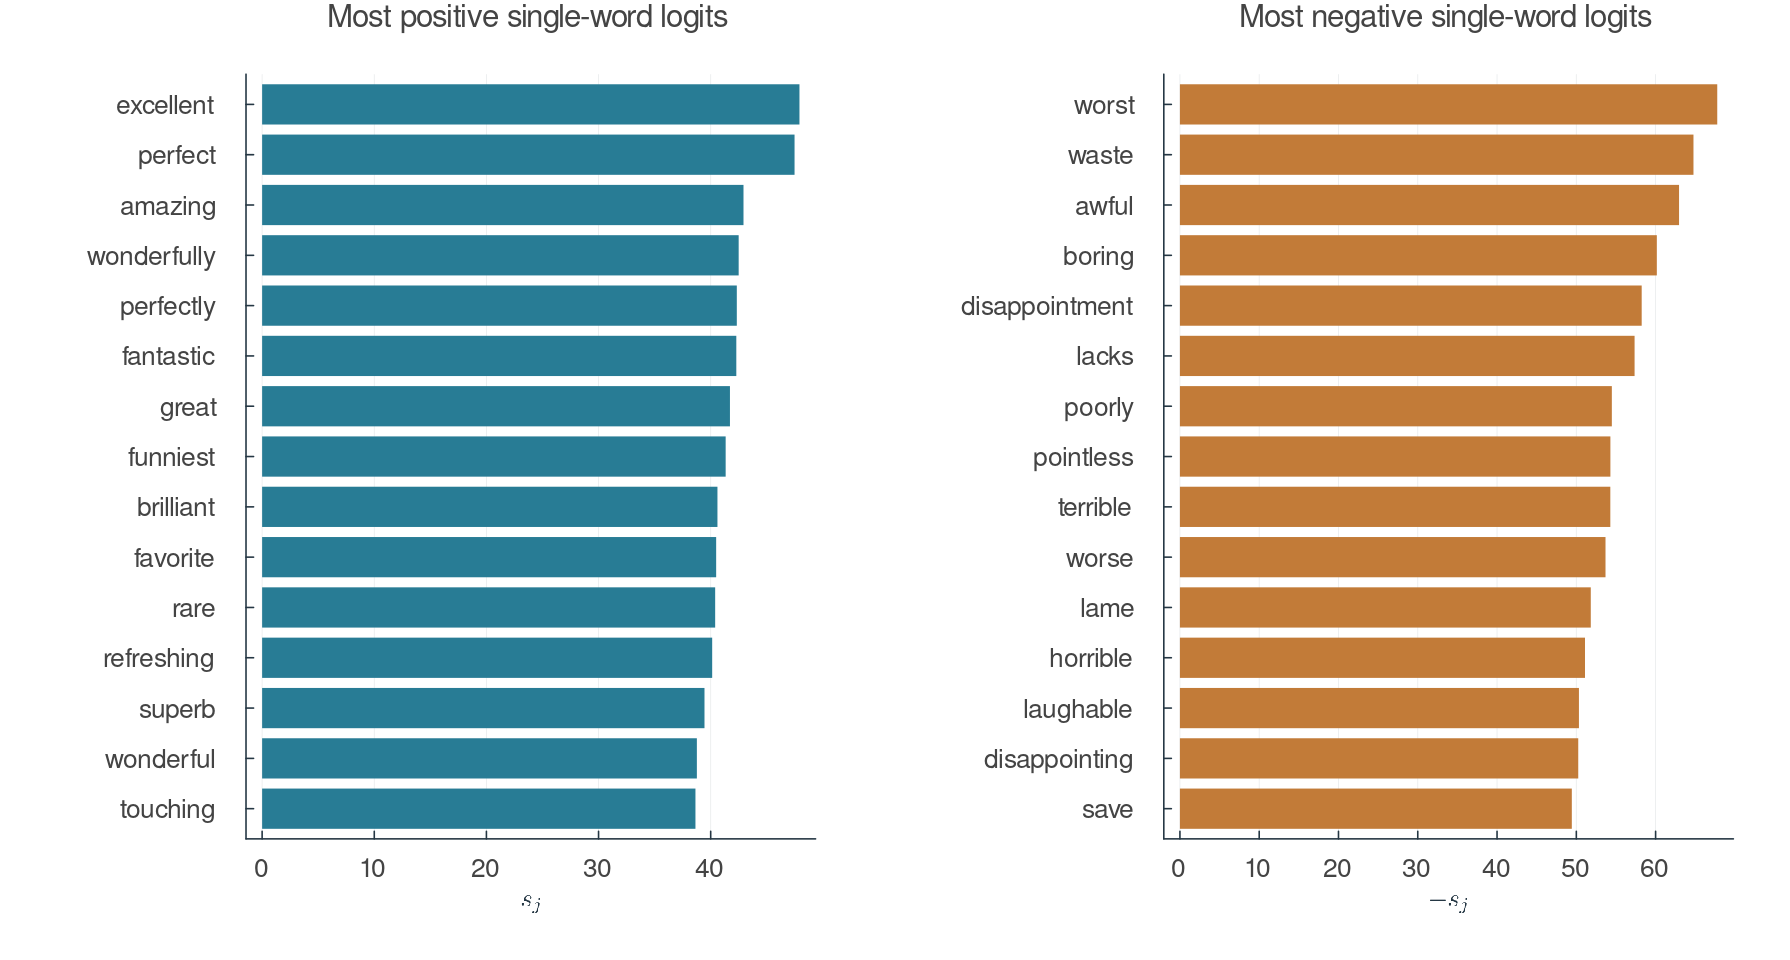

In [20]:
learned=sentiment.model
word_logit=vec(learned.v*max.(learned.W*learned.E .+ learned.b,0f0) .+ learned.c)
doc_freq=vec(sum(imdb.training.F .> 0;dims=2))
frequent=filter(j->j!=1 && doc_freq[j]>=100,1:V_review)
ranked=frequent[sortperm(word_logit[frequent])]
neg_ids,pos_ids=ranked[1:15],reverse(ranked[end-14:end])
@printf("%d frequent words; single-word logits range from %.2f to %.2f\n",
    length(frequent),word_logit[ranked[1]],word_logit[ranked[end]])
bp=bar(word_logit[pos_ids];orientation=:h,yticks=(1:15,imdb.vocab[pos_ids]),yflip=true,
    color=TEAL,linecolor=:transparent,legend=false,title="Most positive single-word logits",
    xlabel=L"s_j",grid=:x,ylims=(0.4,15.6),tickfontsize=11)
bn=bar(-word_logit[neg_ids];orientation=:h,yticks=(1:15,imdb.vocab[neg_ids]),yflip=true,
    color=AMBER,linecolor=:transparent,legend=false,title="Most negative single-word logits",
    xlabel=L"-s_j",grid=:x,ylims=(0.4,15.6),tickfontsize=11)
plot(bp,bn;layout=(1,2),size=(1120,600),left_margin=12Plots.mm)

*Figure 11. Each bar is the trained network's logit for a review made of one word. No word was ever labeled; these scores come entirely from review-level labels and backpropagation through the mean.*

Words with similar roles should end up with similar vectors. Measure closeness with **cosine similarity**,

$$\cos(e_i,e_j)=\frac{e_i^\top e_j}{\lVert e_i\rVert\,\lVert e_j\rVert}\in[-1,1],$$

which compares directions and ignores lengths. The cell lists each probe word's nearest frequent
neighbours in the random initial table and in the learned table.

In [21]:
function nearest_words(E,word;k=6,candidates=frequent)
    j=imdb.lookup[word];e=E[:,j]/norm(E[:,j])
    sims=[dot(e,E[:,i])/norm(E[:,i]) for i in candidates]
    [imdb.vocab[candidates[o]] for o in sortperm(sims;rev=true) if candidates[o]!=j][1:k]
end
for w in ["excellent","awful","boring","beautiful","plot"]
    @printf("%-10s random : %s\n",w,join(nearest_words(sentiment.initial.E,w),", "))
    @printf("%-10s learned: %s\n\n",w,join(nearest_words(learned.E,w),", "))
end

excellent  random : episodes, eddie, exact, she, peter, levels
excellent  learned: perfectly, entertaining, perfect, great, favorite, best

awful      random : success, drags, won, rental, sequels, woods
awful      learned: worse, boring, stupid, waste, disappointment, poorly

boring     random : meanwhile, necessary, wayne, scares, revealed, stick
boring     learned: poorly, unless, awful, disappointment, waste, worse

beautiful  random : serious, bunch, stage, stretch, drunk, multiple
beautiful  learned: fantastic, wonderfully, touching, best, rare, eerie

plot       random : and, hour, bridge, problem, superficial, intense
plot       learned: problem, insult, badly, pointless, shoot, stiff



After training, sentiment words cluster with words of the same polarity, while the random
table's neighbours are arbitrary. Even `plot` now sits among negative words: in IMDb reviews,
complaints tend to discuss the plot, and the loss only rewards information about sentiment.
The vector does not describe what a plot *is*. This is a general principle: **an embedding learns what its training
objective needs**. Word2vec-style embeddings and language models instead predict surrounding
or next words, so their vectors capture broader usage; that is the objective of Part 2.

### 4.5 What averaging cannot represent

The two probe sentences `The movie is good, not bad` and `The movie is bad, not good`
have the same word counts. Therefore they have the same $f$, the same $a=Ef$,
and the same prediction, despite their different word order.
This is the bag-of-words property from Section 2.3. The code below verifies the equality and lists two test-set mistakes.

This is a limitation of this architecture, not a shortage of training epochs.
To model order and context, we need a representation that keeps a separate state at each position.
Short probes also differ from the full reviews used in training; their probabilities are not calibrated guarantees.

In [22]:
function sentiment_probability(text,run=sentiment)
    lookup=Dict(w=>i for (i,w) in enumerate(run.vocab))
    ids=word_ids(text,lookup)
    only(review_forward(run.model,word_frequencies([ids],length(run.vocab))).p)
end
my_reviews=["The actors were wonderful and the story kept me interested.",
    "The plot was confusing and the dialogue was painfully dull.",
    "The movie is good, not bad.","The movie is bad, not good."]
for s in my_reviews
    @printf("P(positive) = %.4f | %s\n",sentiment_probability(s),s)
end
@assert sentiment_probability(my_reviews[3])≈sentiment_probability(my_reviews[4])
mistakes=findall((sentiment.test.probabilities.>=0.5).!=(vec(imdb.test.y).>=0.5))
println("\nFirst two errors in source order (short excerpts):")
for i in first(mistakes,2)
    @printf("label=%d, P(positive)=%.3f: %s…\n",imdb.test.rows[i].y,
        sentiment.test.probabilities[i],first(replace(imdb.test.rows[i].text,r"<[^>]*>"=>" "),130))
end

P(positive) = 0.9980 | The actors were wonderful and the story kept me interested.


P(positive) = 0.0000 | The plot was confusing and the dialogue was painfully dull.
P(positive) = 0.0003 | The movie is good, not bad.
P(positive) = 0.0003 | The movie is bad, not good.



First two errors in source order (short excerpts):
label=0, P(positive)=0.951: First off let me say, If you haven't enjoyed a Van Damme movie since bloodsport, you probably will not like this movie. Most of th…


label=0, P(positive)=0.589: Blind Date (Columbia Pictures, 1934), was a decent film, but I have a few issues with this film. First of all, I don't fault the a…


## 5. From averaging to attention

### 5.1 Mean pooling is a fixed weighting

Write the review vector with explicit weights $\alpha_t$:

$$a=\sum_{t=1}^T\alpha_t\,\tilde e_t,\qquad \alpha_t\geq0,\qquad \sum_{t=1}^T\alpha_t=1.$$

Mean pooling fixes $\alpha_t=1/T$ for every position, whatever word sits there and whatever surrounds it.
That causes both limitations we observed:

1. Every token gets the same weight, so `not` cannot change how much `good` counts.
2. Each word's vector is the same in every context, so the pair (`not`, `good`) is just two separate terms in the sum.

### 5.2 Let the weights depend on the words

**Attention** computes the weights from the token vectors themselves. For each position $i$,
three learned matrices produce a query, a key, and a value:

$$q_i=W_Q\tilde e_i,\qquad k_j=W_K\tilde e_j,\qquad v_j=W_V\tilde e_j.$$

Position $i$ scores every position $j$ by $k_j^\top q_i$, turns those scores into weights with a softmax,
and reads a weighted combination of values:

$$\alpha_{ji}=\frac{\exp(k_j^\top q_i/\sqrt{d_k})}{\sum_{\ell}\exp(k_\ell^\top q_i/\sqrt{d_k})},
\qquad o_i=\sum_{j}\alpha_{ji}\,v_j.$$

Unlike $a$, which is one vector per review, $o_i$ is a **separate context vector for every position**,
so the representation of `good` can depend on a nearby `not`.
Part 2 defines every matrix in this formula, adds the causal mask and a residual connection
$r_i=\tilde e_i+o_i$, and trains the result as a small language model.

Figure 12 makes the contrast concrete on our traced review. The lower panel is **not learned attention**:
it is a hand-built rule, $\alpha_t\propto\exp(|s_{x_t}|/\tau)$ with $\tau=10$, that weights each token by the size of
its single-word logit. It only shows what input-dependent weights look like.

Uniform weight per token: 0.0087 | largest hand-built weight: 0.1825 (annoying)


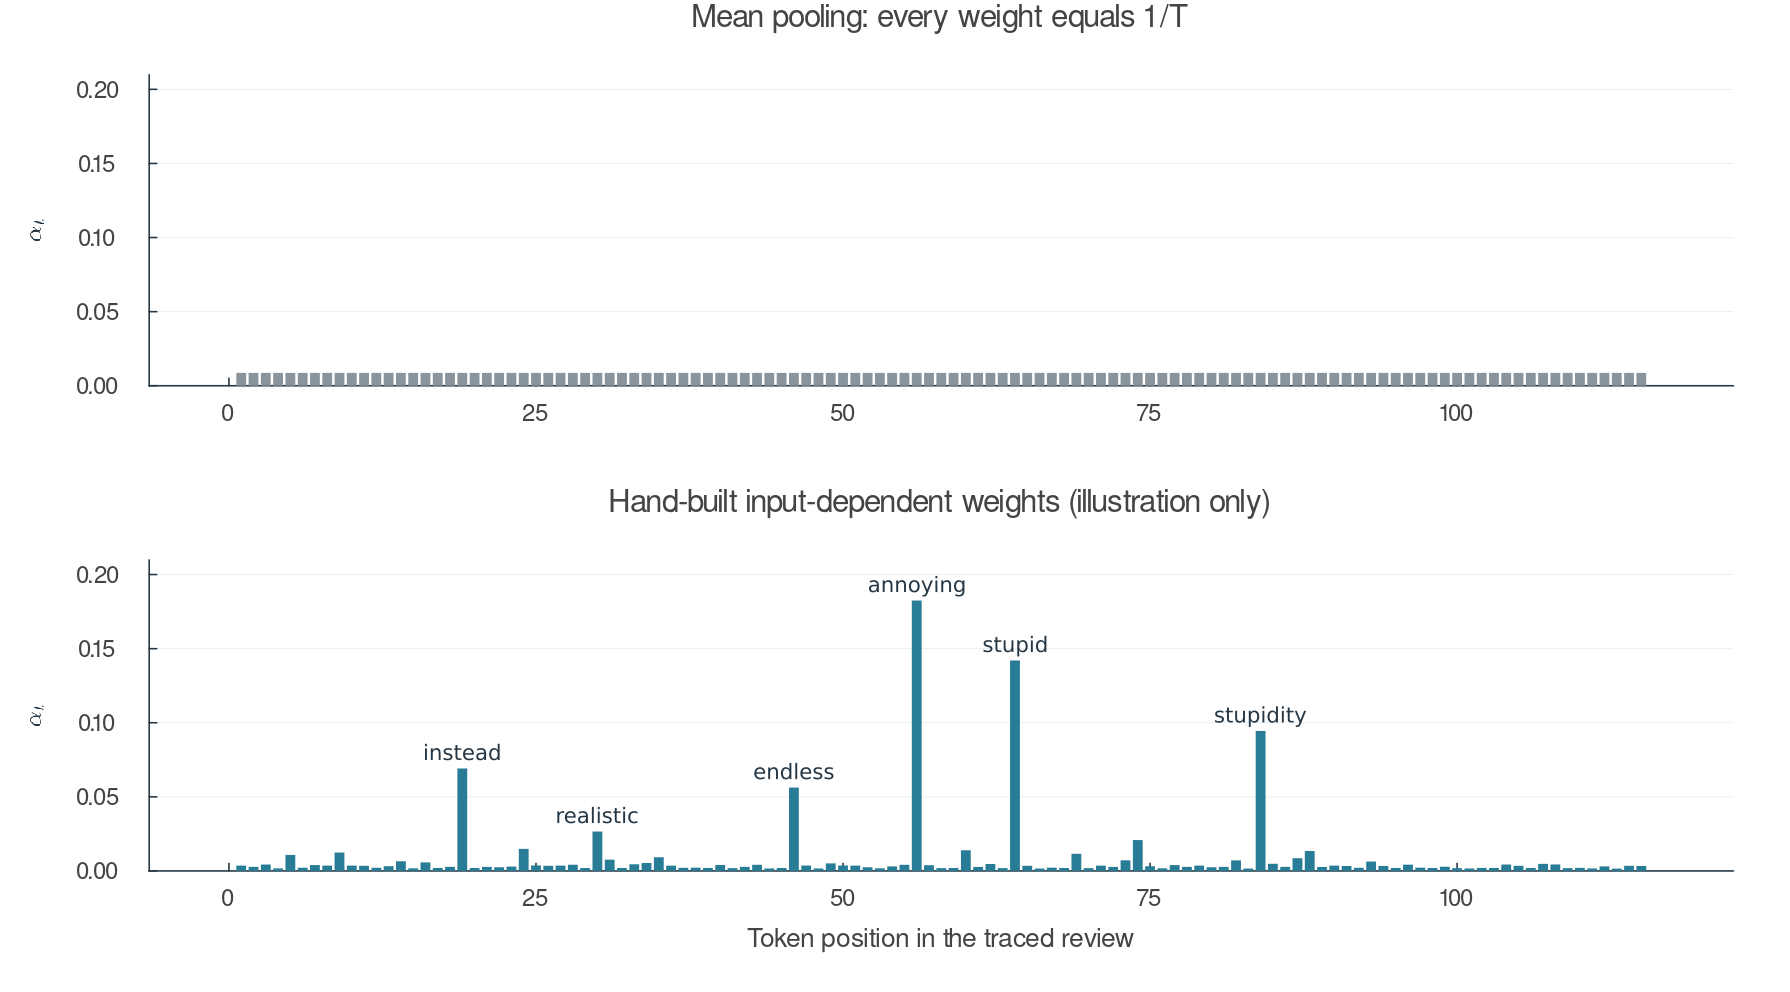

In [23]:
alpha_uniform=fill(1/T_review,T_review)
score_trace=abs.(word_logit[trace_ids])
tau=10f0
alpha_rule=exp.(score_trace./tau)./sum(exp.(score_trace./tau))
top=sortperm(alpha_rule;rev=true)[1:6]
wa=bar(1:T_review,alpha_uniform;color=GRAY,linecolor=:transparent,legend=false,
    ylims=(0,1.15maximum(alpha_rule)),title="Mean pooling: every weight equals 1/T",ylabel=L"\alpha_t",grid=:y)
wb=bar(1:T_review,alpha_rule;color=TEAL,linecolor=:transparent,legend=false,
    ylims=(0,1.15maximum(alpha_rule)),title="Hand-built input-dependent weights (illustration only)",
    xlabel="Token position in the traced review",ylabel=L"\alpha_t",grid=:y)
for t in top
    annotate!(wb,t,alpha_rule[t]+0.06maximum(alpha_rule),text(trace_tokens[t],9,INK))
end
@printf("Uniform weight per token: %.4f | largest hand-built weight: %.4f (%s)\n",
    1/T_review,maximum(alpha_rule),trace_tokens[top[1]])
plot(wa,wb;layout=(2,1),size=(1120,620))

*Figure 12. Both panels weight the same 115 token vectors. Mean pooling spreads weight evenly; an input-dependent rule can concentrate it on informative tokens. Attention learns such weights from data, separately for every position.*

## 6. Check your understanding

1. What distinguishes a token position, a token ID, and an embedding coordinate?
2. What are $E$, $H$, $f$, and $a$? Derive $a=H\mathbf1_T/T=Ef$.
3. Which objects does the optimizer change, and which are recomputed activations?
4. Derive $\partial L/\partial z=\hat p-y$, then $\nabla_E L=\delta_a f^\top$.
5. Why must two reviews with the same word counts receive the same prediction?
6. Write mean pooling as a weighted sum. What does attention change about the weights and the output?

<details><summary>Answer notes</summary>

A position identifies where a token occurs; its ID selects a vocabulary entry; a coordinate
selects a component of its vector. $E$ is the vocabulary table and $H$ selects its columns
with repetition. Averaging those columns equals weighting each vocabulary column by its
observed frequency $f_j$. Parameters persist and are updated; activations are recomputed.
The sigmoid and binary-loss derivatives simplify to $\hat p-y$; differentiating $a=Ef$
then gives $\delta_a f^\top$. Reordering leaves $f$ unchanged, so $a$ and $\hat p$ are unchanged.
Mean pooling is $a=\sum_t\alpha_t\tilde e_t$ with $\alpha_t=1/T$. Attention computes
$\alpha_{ji}$ from queries and keys, so the weights depend on the input, and it returns one output per position.

</details>

### Further reading

[Jurafsky & Martin, *Speech and Language Processing*](https://web.stanford.edu/~jurafsky/slp3/)
(chapters on classification and vector semantics),
[Keras: Text classification from scratch](https://keras.io/examples/nlp/text_classification_from_scratch/), and
[Dive into Deep Learning: sentiment analysis](https://d2l.ai/chapter_natural-language-processing-applications/index.html).